## Midterm Project
- (a) data exploration & EDA 
- (b) Data Preprocessing and Cleaning
- (c) perform training on different models

In [1]:
import subprocess
import shutil

# gpu = subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout if subprocess.run(['which','nvidia-smi'], capture_output=True).returncode == 0 else ''
# print(gpu or 'No Gpu detected: switch the runtime to Gpu before the SVM section training')

if shutil.which("nvidia-smi"):
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True
    )
    gpu = result.stdout
else:
    gpu = ""

print(gpu or "No GPU detected: switch the runtime to GPU before the SVM section training")

Wed Nov 11 21:51:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.88                 KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3050      WDDM  |   00000000:01:00.0  On |                  N/A |
| 30%   27C    P5             16W /   70W |    1448MiB /   6144MiB |     24%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

======================================================================================================
### Download the Dataset
======================================================================================================

In [90]:
# # Only execute once to download dataset
# import subprocess, zipfile
# from pathlib import Path
# DATA_DIR = Path("home-credit-default-risk")
# data_url = (
# "https://www.dropbox.com/scl/fi/86yxnx1e956jztoh5dead/"
# "home-credit-default-risk.zip?rlkey=ezc1chvbo4hw41it6unt20sb2&st=cebvj3ln&dl=1"
# )
# # Download the dataset zip with wget, then extract it into DATA_DIR
# subprocess.run(["wget", "-O", "home-credit-default-risk.zip", data_url], check=True)
# with zipfile.ZipFile("home-credit-default-risk.zip") as archive:
#  archive.extractall(DATA_DIR)


In [2]:
import os, gc, re, time, warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns',200)
pd.set_option('display.width',200)
sns.set_theme(style='whitegrid', context = 'notebook')

blue = '#4C72B0'
orange = '#DD8500'
green = '#55A868'
red = '#C44E52'
#plt.rcParams['axes.grid'] = False
CONFIG = {
    'threshold': 0.5,                         # decision threshold on predicted probability
    'sub_dir': 'submissions',                 # Kaggle submission CSVs
    'seed': 42,
    'data_dir': 'home-credit-default-risk',   # relative path: works on Colab and Kaggle
    'out_dir': 'processed',
    'val_size': 0.20,                         # stratified train/validation split
    'days_placeholder': 365243,               # dataset's code for "not applicable" in DAYS_* columns
    'rare_category_share': 0.01,              # aux-table categories rarer than this -> 'Other'
    'recent_months': 12,                      # window for "recent" monthly-balance behaviour
    'recent_days': 365,                       # window for "recent" instalment behaviour
    'prep': dict(max_missing=0.80, max_mode_share=0.995, indicator_min_missing=0.05,
                 clip_q=(0.001, 0.999), skew_threshold=2.0, corr_threshold=0.98, min_cat_freq=0.005),
}
DAYS_PLACEHOLDER = CONFIG['days_placeholder']
SEED = CONFIG['seed']
np.random.seed(SEED)
DATA_DIR = Path(CONFIG['data_dir']) # raw kaggle csvs file location
OUT_DIR = Path(CONFIG['out_dir']) # model-ready arrays written at the end and save to here
#os.makedirs(DATA_DIR,exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

### explanation of imported packages
- os Manage file paths and directories
- gc Garbage collection; helps release unused memory
- re Regular expressions for text processing
- time Measure code execution time
- warnings Control warning messages
- numpy(np) Numerical computation and arrays
- pandas (np) Load, clean, and manimulpate tabular data
- seaborn (sns) Statistical data visualization
- train_test_split Split data into training and test sets
- OneHotEncoder Convert categorical features into numerical columns
- StandardScalar Standardize numercial features

======================================================================================================
### Data Exploration & Exploratory Data Analysis (EDA)
#### Structure and data types

In [3]:
def load(name, cat=False, **kw):
    """
    1. read a csv and shrink memory: float64 -> float32, int64 -> int32 (all IDs < 2^31)
    2. optional strings -> category (used for the large auxiliary tables)
    3. **kw means allows a function to accept any number of named keyword arguments
    4. convert float64 -> float32 to save memory
    """
    df = pd.read_csv(f'{DATA_DIR}/{name}.csv', **kw)
    for c in df.columns:
        t = df[c].dtype
        if t == 'float64':
            df[c] = df[c].astype('float32')
        elif t == 'int64':
            df[c] = df[c].astype('int32')
        elif cat and not pd.api.types.is_numeric_dtype(t):
            df[c] = df[c].astype('category')
    return df
def mem(df):
    #total memory usage for the dataset
    return f'{df.memory_usage(deep=True).sum() / 1e6:,.0f} MB'

======================================================================================================
#### A.1. Structure and data types
======================================================================================================

In [4]:
"""
assert check that TARGET is the only column present in app_train but not app_test 
app_test is reserved for kaggle score 
"""

app_train = load('application_train')
app_test = load('application_test')

print('application_train: ', app_train.shape, mem(app_train))
print('application_test: ', app_test.shape, mem(app_test))

assert set(app_train.columns) - set(app_test.columns) == {'TARGET'}
assert app_train.SK_ID_CURR.is_unique and app_test.SK_ID_CURR.is_unique

num_cols_raw = app_train.select_dtypes('number').columns.drop(['SK_ID_CURR','TARGET']).tolist()
cat_cols_raw = app_train.select_dtypes(exclude='number').columns.tolist()
flag_cols = [c for c in num_cols_raw if app_train[c].dropna().isin([0,1]).all()]
print(f'{len(num_cols_raw)} numeric columns ({len(flag_cols)} of them are 0/1 flags, {len(cat_cols_raw)} categorical columns)')
display(app_train.head(10)) # present first 10 rows
display(app_train[cat_cols_raw].nunique().sort_values(ascending=False).to_frame('n_levels').T)


application_train:  (307511, 122) 211 MB
application_test:  (48744, 121) 33 MB
104 numeric columns (32 of them are 0/1 flags, 16 categorical columns)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

,ORGANIZATION_TYPE,OCCUPATION_TYPE,NAME_INCOME_TYPE,NAME_TYPE_SUITE,WALLSMATERIAL_MODE,WEEKDAY_APPR_PROCESS_START,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,NAME_EDUCATION_TYPE,FONDKAPREMONT_MODE,HOUSETYPE_MODE,CODE_GENDER,FLAG_OWN_CAR,NAME_CONTRACT_TYPE,FLAG_OWN_REALTY,EMERGENCYSTATE_MODE
n_levels,58,18,8,7,7,7,6,6,5,4,3,3,2,2,2,2


#### A.2.Target Balance
- evaluate 0/1 categorical values ratio in application_train dataset

         count   share
TARGET                
0       282686  0.9193
1        24825  0.0807
Accuracy of always predicting 'repaid':0.919
Imbalance ratio: 11.4 : 1


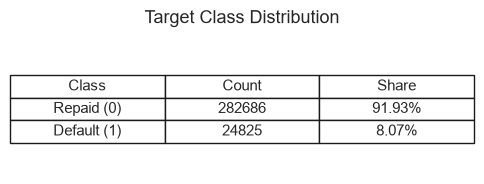

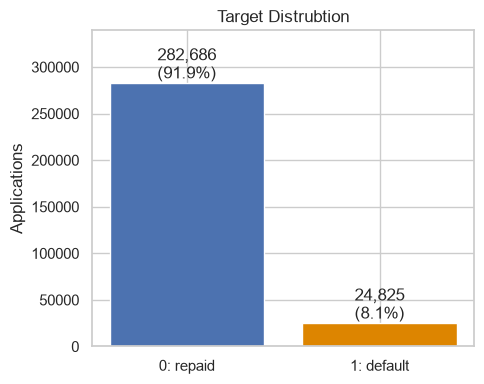

In [5]:
vc = app_train.TARGET.value_counts().sort_index()
print(pd.DataFrame({'count': vc, 'share': (vc/vc.sum()).round(4)}))
print(f'Accuracy of always predicting \'repaid\':{vc[0]/vc.sum():.3f}')
print(f'Imbalance ratio: {vc[0] / vc[1]:.1f} : 1')

#create a table for it
df = pd.DataFrame({
    'Class': ['Repaid (0)','Default (1)'],
    'Count': vc.values,
    'Share': (vc / vc.sum()).map('{:.2%}'.format)
})
accuracy = vc[0] /vc.sum()
imbalance = vc[0] / vc[1]
fig, ax0 = plt.subplots(figsize=(5,2))
ax0.axis('off')

table = ax0.table(
    cellText=df.values.tolist(), # to fix the type error 
    colLabels=df.columns.tolist(),
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1,1.6)
ax0.set_title('Target Class Distribution', fontsize=13, pad=15)
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(5,4))
ax.bar(['0: repaid','1: default'], vc.values, color=[blue,orange])
for i ,v in enumerate(vc.values):
    ax.text(i, v, f'{v:,}\n({v / vc.sum():.1%})', ha='center', va='bottom')
ax.set_ylabel('Applications'); ax.set_title('Target Distrubtion'); ax.set_ylim(0,vc.max()*1.2)
plt.tight_layout(); 
plt.show()


======================================================================================================
#### A.3.Missing values evaluation
======================================================================================================

67 of 122 columns contain missing values: 41 are more than 50% missing ratio.


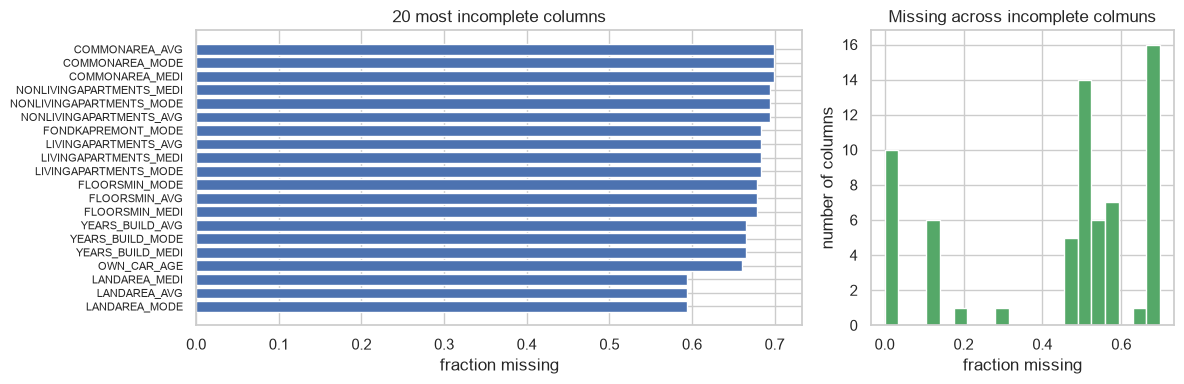

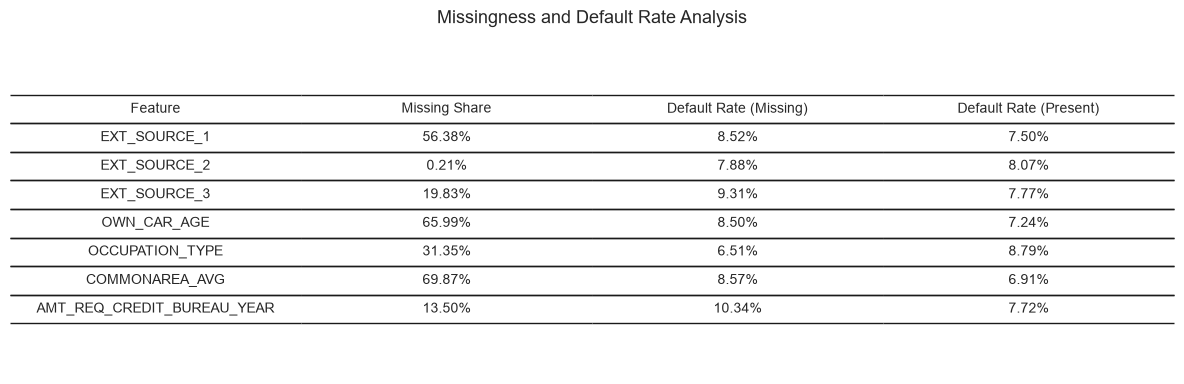

In [6]:
miss = app_train.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print(f'{len(miss)} of {app_train.shape[1]} columns contain missing values: '
      f'{(miss > 0.5).sum()} are more than 50% missing ratio.'
      ) # 0 is row 1: column

fig, axes = plt.subplots(1,2, figsize = (12,4), gridspec_kw={'width_ratios':[2,1]})
top=miss.head(20)[::-1]
axes[0].barh(top.index, top.values, color=blue)
axes[0].set_xlabel('fraction missing'); axes[0].set_title('20 most incomplete columns')
axes[0].tick_params(axis='y', labelsize=8)
axes[1].hist(miss.values,bins=20, color = green)
axes[1].set_xlabel('fraction missing'); axes[1].set_ylabel('number of columns')
axes[1].set_title('Missing across incomplete colmuns')
plt.tight_layout()
plt.show()


# Check for informative missingness to decide if we should engineer 
# binary missingness indicator features (e.g., _is_missing) for our models.
check = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'OWN_CAR_AGE', 'OCCUPATION_TYPE',
         'COMMONAREA_AVG', 'AMT_REQ_CREDIT_BUREAU_YEAR']
rows = []
for c in check:
    m = app_train[c].isna()
    rows.append({
        'feature':c,
        'missing_share':m.mean(),
        'default_rate_if_missing':app_train.TARGET[m].mean(),
        'default_rate_if_present':app_train.TARGET[~m].mean()
    })


# Convert to DataFrame
df = pd.DataFrame(rows)

# Format percentages
df_plot = df.copy()
for c in df_plot.columns[1:]:
    df_plot[c] = df_plot[c].map('{:.2%}'.format)

# Create table
fig, ax = plt.subplots(figsize=(12, 4))
ax.axis('off')

table = ax.table(
    cellText=df_plot.values.tolist(),
    colLabels=[
        'Feature',
        'Missing Share',
        'Default Rate (Missing)',
        'Default Rate (Present)'
    ],
    loc='center',
    cellLoc='center',
    edges='horizontal'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.6)

ax.set_title('Missingness and Default Rate Analysis',
             fontsize=13, pad=15)

plt.tight_layout()
plt.show()


======================================================================================================
#### A.4.Statistic summary and anomalies
======================================================================================================

,count,mean,std,min,1%,50%,99%,max
AMT_INCOME_TOTAL,307511.0,168797.92,237123.14,25650.00,45000.00,147150.00,472500.00,1.170000e+08
AMT_CREDIT,307511.0,599026.00,402490.78,45000.00,76410.00,513531.00,1854000.00,4.050000e+06
AMT_ANNUITY,307499.0,27108.57,14493.74,1615.50,6182.91,24903.00,70006.50,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.19,369446.47,40500.00,67500.00,450000.00,1800000.00,4.050000e+06
DAYS_BIRTH,307511.0,-16037.00,4363.99,-25229.00,-24419.00,-15750.00,-8263.00,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.05,141275.77,-17912.00,-10894.90,-1213.00,365243.00,3.652430e+05
DAYS_REGISTRATION,307511.0,-4986.12,3522.89,-24672.00,-13879.00,-4504.00,-50.00,0.000000e+00
DAYS_ID_PUBLISH,307511.0,-2994.20,1509.45,-7197.00,-5447.00,-3254.00,-61.00,0.000000e+00
CNT_CHILDREN,307511.0,0.42,0.72,0.00,0.00,0.00,3.00,1.900000e+01
CNT_FAM_MEMBERS,307509.0,2.15,0.91,1.00,1.00,2.00,5.00,2.000000e+01


,Group,Missing %,Mean,Std,Min,P1,Median,P99,Max,Skew
Features,,,,,,,,,,
AMT_INCOME_TOTAL,Monetary,0.0,"168,797.92","237,123.14","25,650.00","45,000.00","147,150.00","472,500.00","117,000,000.00",391.6
AMT_CREDIT,Monetary,0.0,"599,026.00","402,490.78","45,000.00","76,410.00","513,531.00","1,854,000.00","4,050,000.00",1.2
AMT_ANNUITY,Monetary,0.0,"27,108.57","14,493.74","1,615.50","6,182.91","24,903.00","70,006.50","258,025.50",1.6
AMT_GOODS_PRICE,Monetary,0.1,"538,396.19","369,446.47","40,500.00","67,500.00","450,000.00","1,800,000.00","4,050,000.00",1.3
DAYS_BIRTH,Temporal (days before application),0.0,"-16,037.00","4,363.99","-25,229.00","-24,419.00","-15,750.00","-8,263.00","-7,489.00",-0.1
DAYS_EMPLOYED,Temporal (days before application),0.0,"63,815.05","141,275.77","-17,912.00","-10,894.90","-1,213.00","365,243.00","365,243.00",1.7
DAYS_REGISTRATION,Temporal (days before application),0.0,"-4,986.12","3,522.89","-24,672.00","-13,879.00","-4,504.00",-50.00,0.00,-0.6
DAYS_ID_PUBLISH,Temporal (days before application),0.0,"-2,994.20","1,509.45","-7,197.00","-5,447.00","-3,254.00",-61.00,0.00,0.3
CNT_CHILDREN,Household,0.0,0.42,0.72,0.00,0.00,0.00,3.00,19.00,2.0


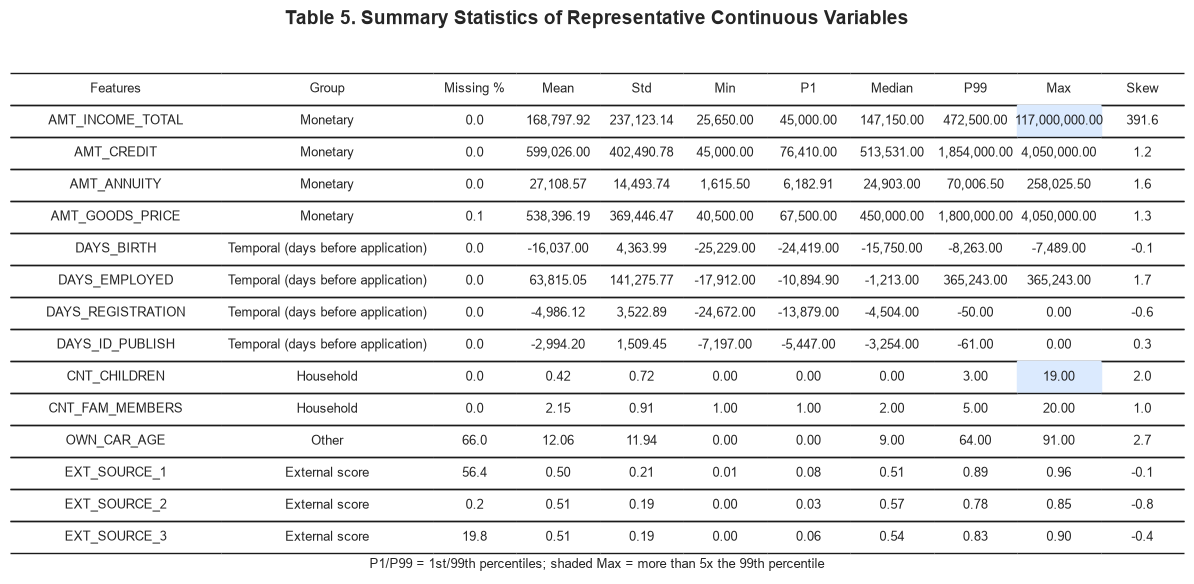

In [7]:
key_features = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
           'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'OWN_CAR_AGE',
           'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
desc = app_train[key_features].describe(percentiles=[0.01,0.5,0.99]).T
display(desc.round(2))

groups = (['Monetary']*4+ ['Temporal (days before application)']*4+['Household']*2+['Other']+['External score']*3)
summary = pd.DataFrame({
    'Group': groups,
    'Missing %': app_train[key_features].isna().mean().mul(100).values,
    'Mean': desc['mean'].values,
    'Std': desc['std'].values,
    'Min': desc['min'].values,
    'P1': desc['1%'].values,
    'Median':desc['50%'].values,
    'P99':desc['99%'].values,
    'Max': desc['max'].values,
    'Skew': app_train[key_features].skew().values
},

index = pd.Index(key_features, name="Features")
)

table4 = (summary.style
          .format('{:,.2f}', subset=['Mean', 'Std', 'Min', 'P1', 'Median', 'P99', 'Max'])
          .format('{:,.1f}', subset=['Missing %', 'Skew'])
          #highlight colmuns where the maxis far beyond the 99th percentile(outliers)
          .apply(lambda r: ['background-color: #dbeafe' if (c == 'Max' and abs(r['Max']) > 5 * abs(r['P99']) and r['P99'] != 0) else ''
                            for c in r.index], axis=1)
        .set_caption('Table 4. Summary statistics of representative continuous variables '
                       '(P1/P99 = 1st/99th percentiles; shaded Max = more than 5x the 99th percentile)')
          .set_table_styles([{'selector': 'caption',
                              'props': 'caption-side: top; font-weight: bold; font-size: 1.05em; text-align: left;'}]))
display(table4)

# Keep feature names as a column
df_plot = summary.reset_index().copy()

# Highlight outliers: Max > 5 × P99
outliers = (
    (summary['P99'] != 0) &
    (summary['Max'].abs() > 5 * summary['P99'].abs())
)

# Format numeric columns
num_cols = ['Mean', 'Std', 'Min', 'P1',
            'Median', 'P99', 'Max']

for c in num_cols:
    df_plot[c] = df_plot[c].map('{:,.2f}'.format)

for c in ['Missing %', 'Skew']:
    df_plot[c] = df_plot[c].map('{:,.1f}'.format)

# Create table
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis('off')
ax.grid(False)

table = ax.table(
    cellText=df_plot.values.tolist(),
    colLabels=df_plot.columns.tolist(),
    loc='center',
    cellLoc='center',
    edges='horizontal'
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.7)

# Highlight Max column for outliers
#max_col = df_plot.columns.get_loc('Max')
max_col = df_plot.columns.tolist().index('Max')

for i, is_outlier in enumerate(outliers):
    if is_outlier:
        #table[(i + 1, max_col)].set_facecolor(	'#dbeafe')
        cell = table[(i+1,max_col)]
        cell.set_facecolor('#dbeafe')
        cell.visible_edges='closed'
        cell.set_edgecolor('#dbeafe')

# Adjust column widths
for i, col in enumerate(df_plot.columns):
    width = 0.19 if col in ['Features', 'Group'] else 0.075

    for row in range(len(df_plot) + 1):
        table[(row, i)].set_width(width)

ax.set_title(
    'Table 5. Summary Statistics of Representative Continuous Variables',
    fontsize=14,
    fontweight='bold',
    pad=20
)

fig.text(
    0.5, 0.04,
    'P1/P99 = 1st/99th percentiles; shaded Max = more than 5x the 99th percentile',
    ha='center',
    fontsize=9
)
plt.tight_layout()
plt.show()

======================================================================================================
#### A.5.Anomaly Detection and Analysis after statistic summary
======================================================================================================

Based on the summary table above, we noticed a few unusual values that need to be handled before we train our models:

- **`DAYS_EMPLOYED`:** The maximum value is 365,243 days (which is roughly 1,000 years!). Since this is physically impossible, it's clearly a placeholder code for unemployed or retired applicants.

To begin our data cleaning process, we will address the `DAYS_EMPLOYED` anomaly.

DAYS_EMPLOYED == 365243 in 55,374 rows(18.0%)
Default rate: anomalous 0.0540 vs others 0.0866
NAME_INCOME_TYPE anomalous rows: 
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64
test set: 19.0% anomalous


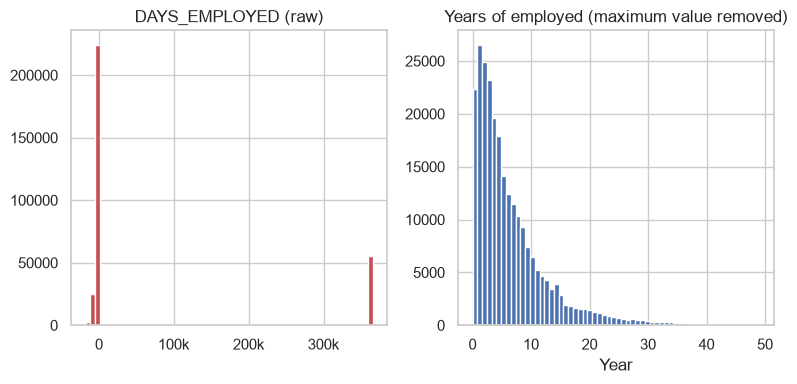


 CODE_GENDER:  {'F': 202448, 'M': 105059, 'XNA': 4}
ORGANIZATION_TYPE=="XNA":  55374 )

Largest incomes:  [117000000, 18000090, 13500000, 9000000, 6750000]
Skewness of monetary columns: 
AMT_INCOME_TOTAL    391.600006
AMT_CREDIT            1.200000
AMT_ANNUITY           1.600000
AMT_GOODS_PRICE       1.300000
dtype: float32


In [8]:
anom = app_train.DAYS_EMPLOYED == 365243
print(f'DAYS_EMPLOYED == 365243 in {anom.sum():,} rows({anom.mean():.1%})') # add thousands separators; add percentage
print(f'Default rate: anomalous {app_train.TARGET[anom].mean():.4f} vs others {app_train.TARGET[~anom].mean():.4f}')
print('NAME_INCOME_TYPE anomalous rows: ');
print(app_train.loc[anom, 'NAME_INCOME_TYPE'].value_counts().head())
print(f'test set: {(app_test.DAYS_EMPLOYED==365243).mean():.1%} anomalous')

fig, axes = plt.subplots(1,2, figsize=(8,4))
axes[0].hist(app_train.DAYS_EMPLOYED, bins=60, color=red)
# reduce the x-axis scale by x/1000 -> xk
axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x/1000:g}k' if x != 0 else '0')
)
axes[0].set_title('DAYS_EMPLOYED (raw)')
axes[1].hist(-app_train.loc[~anom, 'DAYS_EMPLOYED'] / 365, bins=60, color=blue)
axes[1].set_title('Years of employed (maximum value removed)')
axes[1].set_xlabel('Year')
plt.tight_layout()
plt.show()

# amomaly 2 : placeholder categories
print('\n CODE_GENDER: ', app_train.CODE_GENDER.value_counts().to_dict())
print('ORGANIZATION_TYPE=="XNA": ', ((app_train.ORGANIZATION_TYPE=='XNA')& anom).sum(), ')')

#amonaly 3: extreme incomes / heavy tails
print('\nLargest incomes: ', app_train.AMT_INCOME_TOTAL.nlargest(5).astype(int).tolist())
print('Skewness of monetary columns: ')
print(app_train[['AMT_INCOME_TOTAL','AMT_CREDIT','AMT_ANNUITY','AMT_GOODS_PRICE']].skew().round(1))


======================================================================================================
#### A.6.Distribution by Target
======================================================================================================

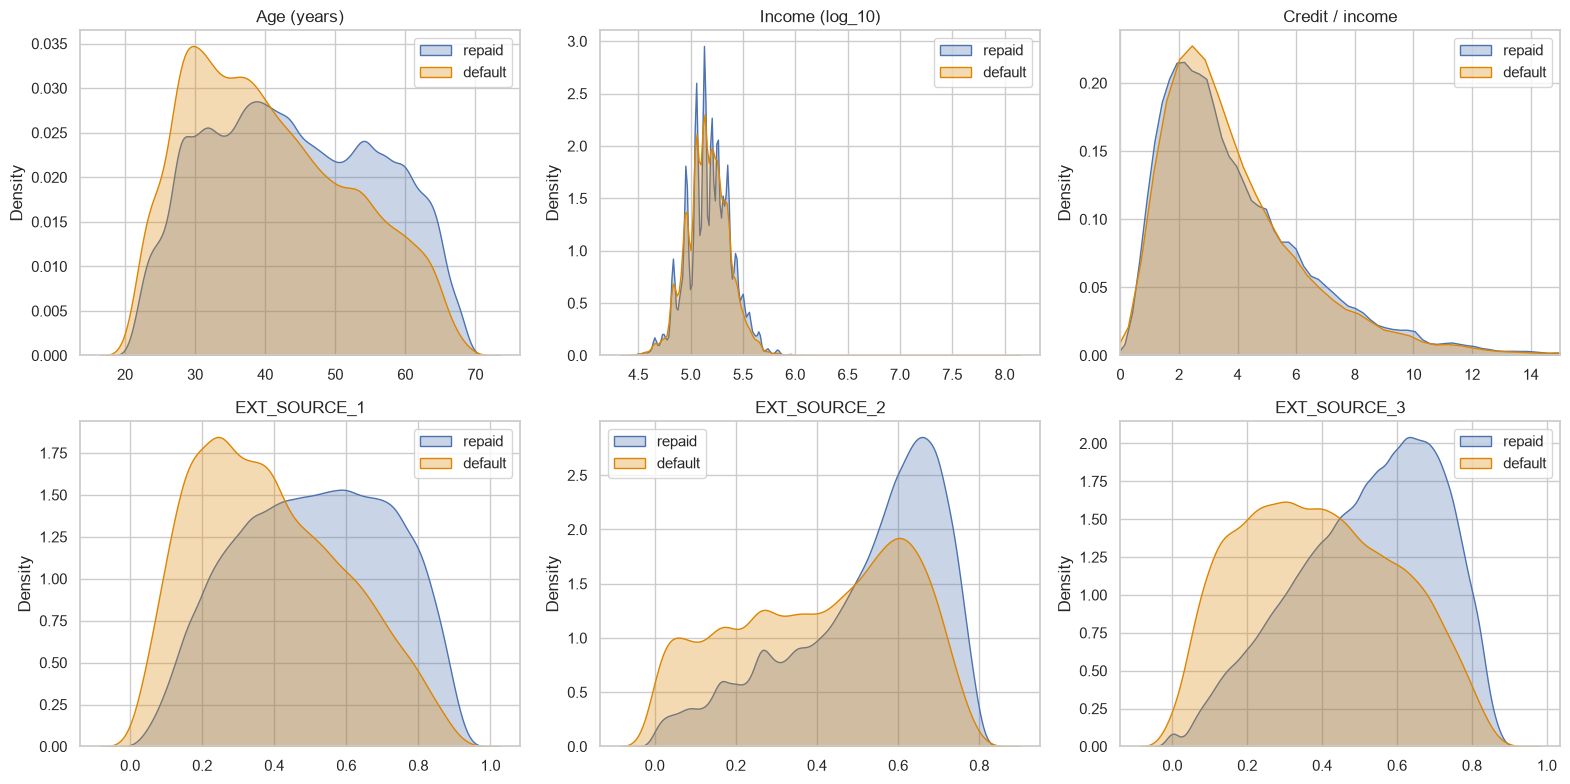

In [9]:
def kde_by_target(ax, s, title, log=False):
    s = np.log10(s.clip(lower=1)) if log else s
    for t, lab, col in [(0, 'repaid', blue), (1, 'default', orange)]:
        sns.kdeplot(s[app_train.TARGET == t].dropna(), ax=ax, label=lab, color=col, fill=True,
                    alpha=.3, common_norm=False)
    ax.set_title(title); ax.set_xlabel(''); ax.legend()

fig, axes = plt.subplots(2,3,figsize=(16,8))
kde_by_target(axes[0, 0], -app_train.DAYS_BIRTH / 365, 'Age (years)')
kde_by_target(axes[0,1], app_train.AMT_INCOME_TOTAL, 'Income (log_10)', log=True)
kde_by_target(axes[0,2], app_train.AMT_CREDIT / app_train.AMT_INCOME_TOTAL, 'Credit / income')
axes[0,2].set_xlim(0,15)
for i,c in enumerate(['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']):
    kde_by_target(axes[1,i], app_train[c],c)
plt.tight_layout()
plt.show()


======================================================================================================
#### A.7.Correlation
======================================================================================================

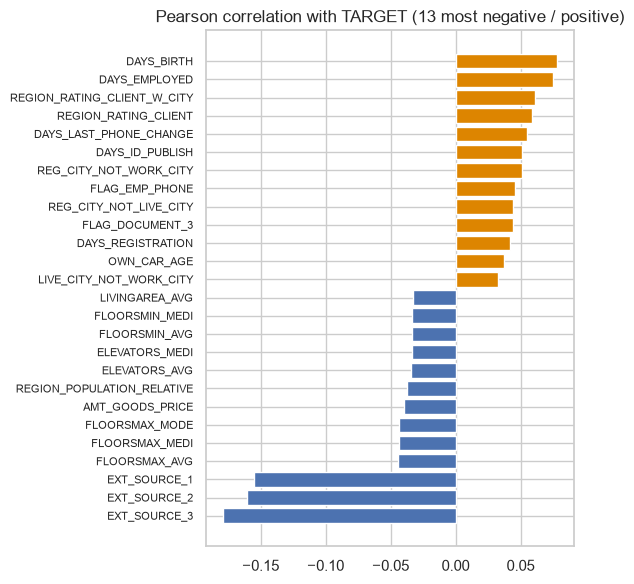

In [10]:
corr_df = app_train.select_dtypes('number').drop(columns=['SK_ID_CURR']).copy() # only select the numerical columns and remove applicant ID
corr_df.loc[corr_df.DAYS_EMPLOYED==365243, 'DAYS_EMPLOYED'] = np.nan # with anomaly of 365243 the value replaces by NaN
corr_t = corr_df.drop(columns='TARGET').corrwith(corr_df.TARGET).dropna().sort_values()

top_corr = pd.concat([corr_t.head(13), corr_t.tail(13)])
fig, ax = plt.subplots(figsize=(6,6))
ax.barh(top_corr.index, top_corr.values,color=np.where(top_corr.values < 0, blue, orange))
ax.set_title('Pearson correlation with TARGET (13 most negative / positive)')
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()


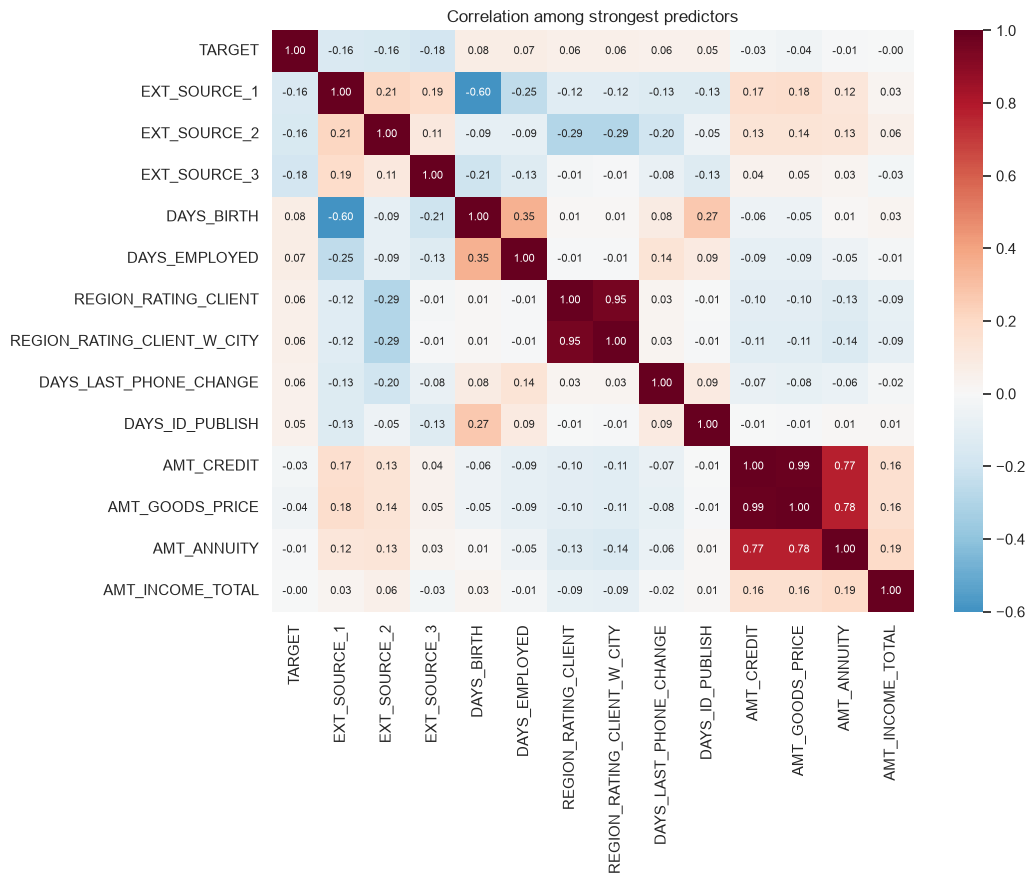

Numeric feature pairs with |r| > 0.95: 45  (mostly the building *_AVG / *_MODE / *_MEDI triplets, plus AMT_CREDIT vs AMT_GOODS_PRICE)


In [11]:
heat_cols = ['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
             'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'DAYS_LAST_PHONE_CHANGE', 'DAYS_ID_PUBLISH',
             'AMT_CREDIT', 'AMT_GOODS_PRICE', 'AMT_ANNUITY', 'AMT_INCOME_TOTAL']
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_df[heat_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax,
            annot_kws={'size': 8})
ax.set_title('Correlation among strongest predictors'); plt.tight_layout(); plt.show()

# How much redundancy is there among numeric features?
C = corr_df.drop(columns='TARGET').corr().abs().values
iu = np.triu_indices_from(C, k=1)
print(f'Numeric feature pairs with |r| > 0.95: {(C[iu] > 0.95).sum()}  '
      '(mostly the building *_AVG / *_MODE / *_MEDI triplets, plus AMT_CREDIT vs AMT_GOODS_PRICE)')
del corr_df, C; _ = gc.collect()

======================================================================================================
#### A.8.Default rate by Categorical features
- Chooe the top 10 categorical features using mutual information, it may introduce the error, but the choice is based on alogrithm
- $I(X; Y) = H(Y) - H(Y|X)$
- $X$: A categorical feature
- $Y$: the binary targt (TARGET= 0,1)
- $H(Y)$: entropy (uncertainty) of the target before observing the feature.
- $H(Y|X)$: remaining uncertainty about the target after ovserving the feature
- High MI means the feature provides more information about the target

Total categorical features: 16

Top 10 categorical features:
OCCUPATION_TYPE        0.0031
ORGANIZATION_TYPE      0.0027
NAME_INCOME_TYPE       0.0021
NAME_EDUCATION_TYPE    0.0018
CODE_GENDER            0.0015
WALLSMATERIAL_MODE     0.0010
EMERGENCYSTATE_MODE    0.0009
HOUSETYPE_MODE         0.0008
NAME_FAMILY_STATUS     0.0008
NAME_HOUSING_TYPE      0.0006
Name: Mutual Information, dtype: float64


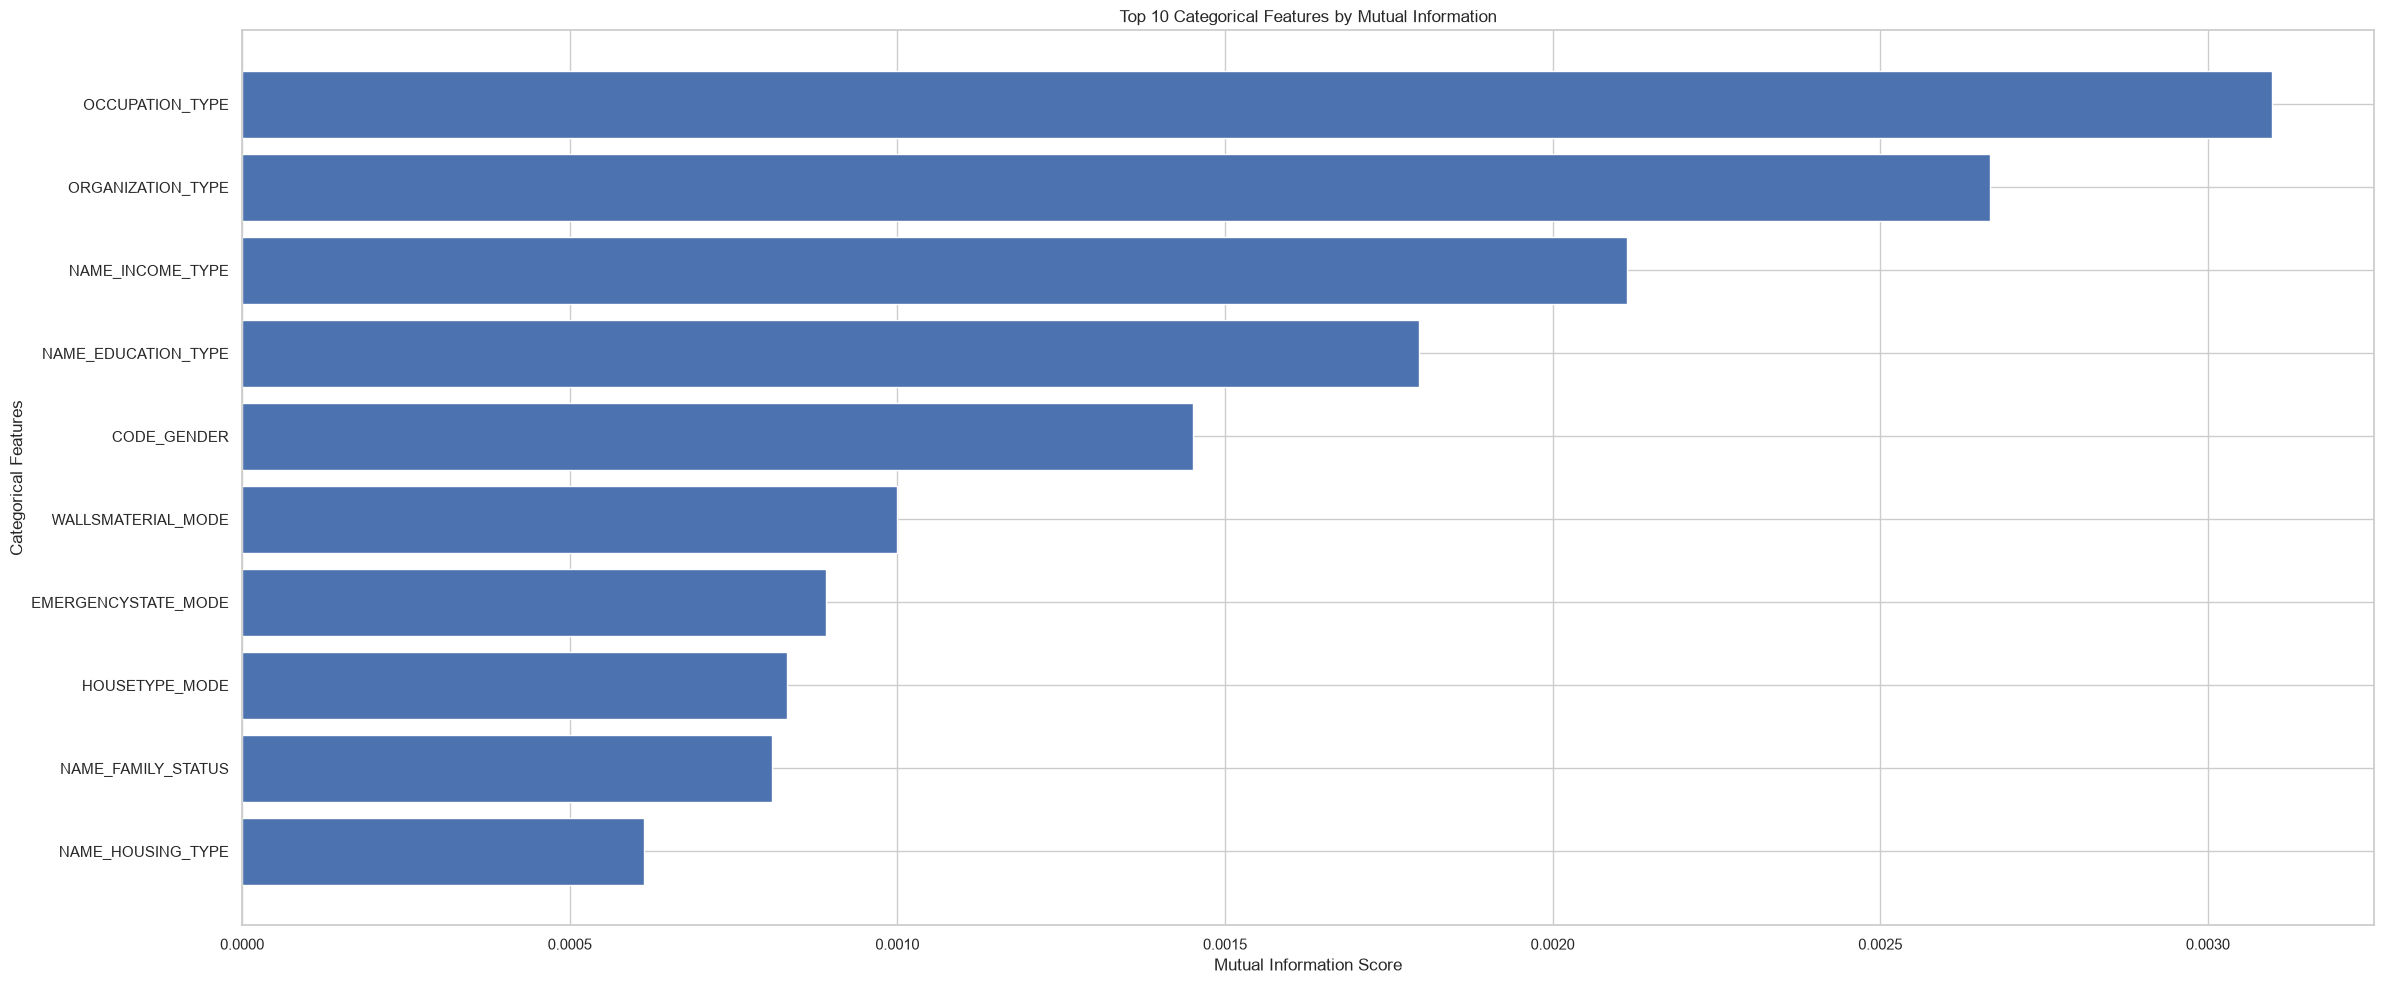

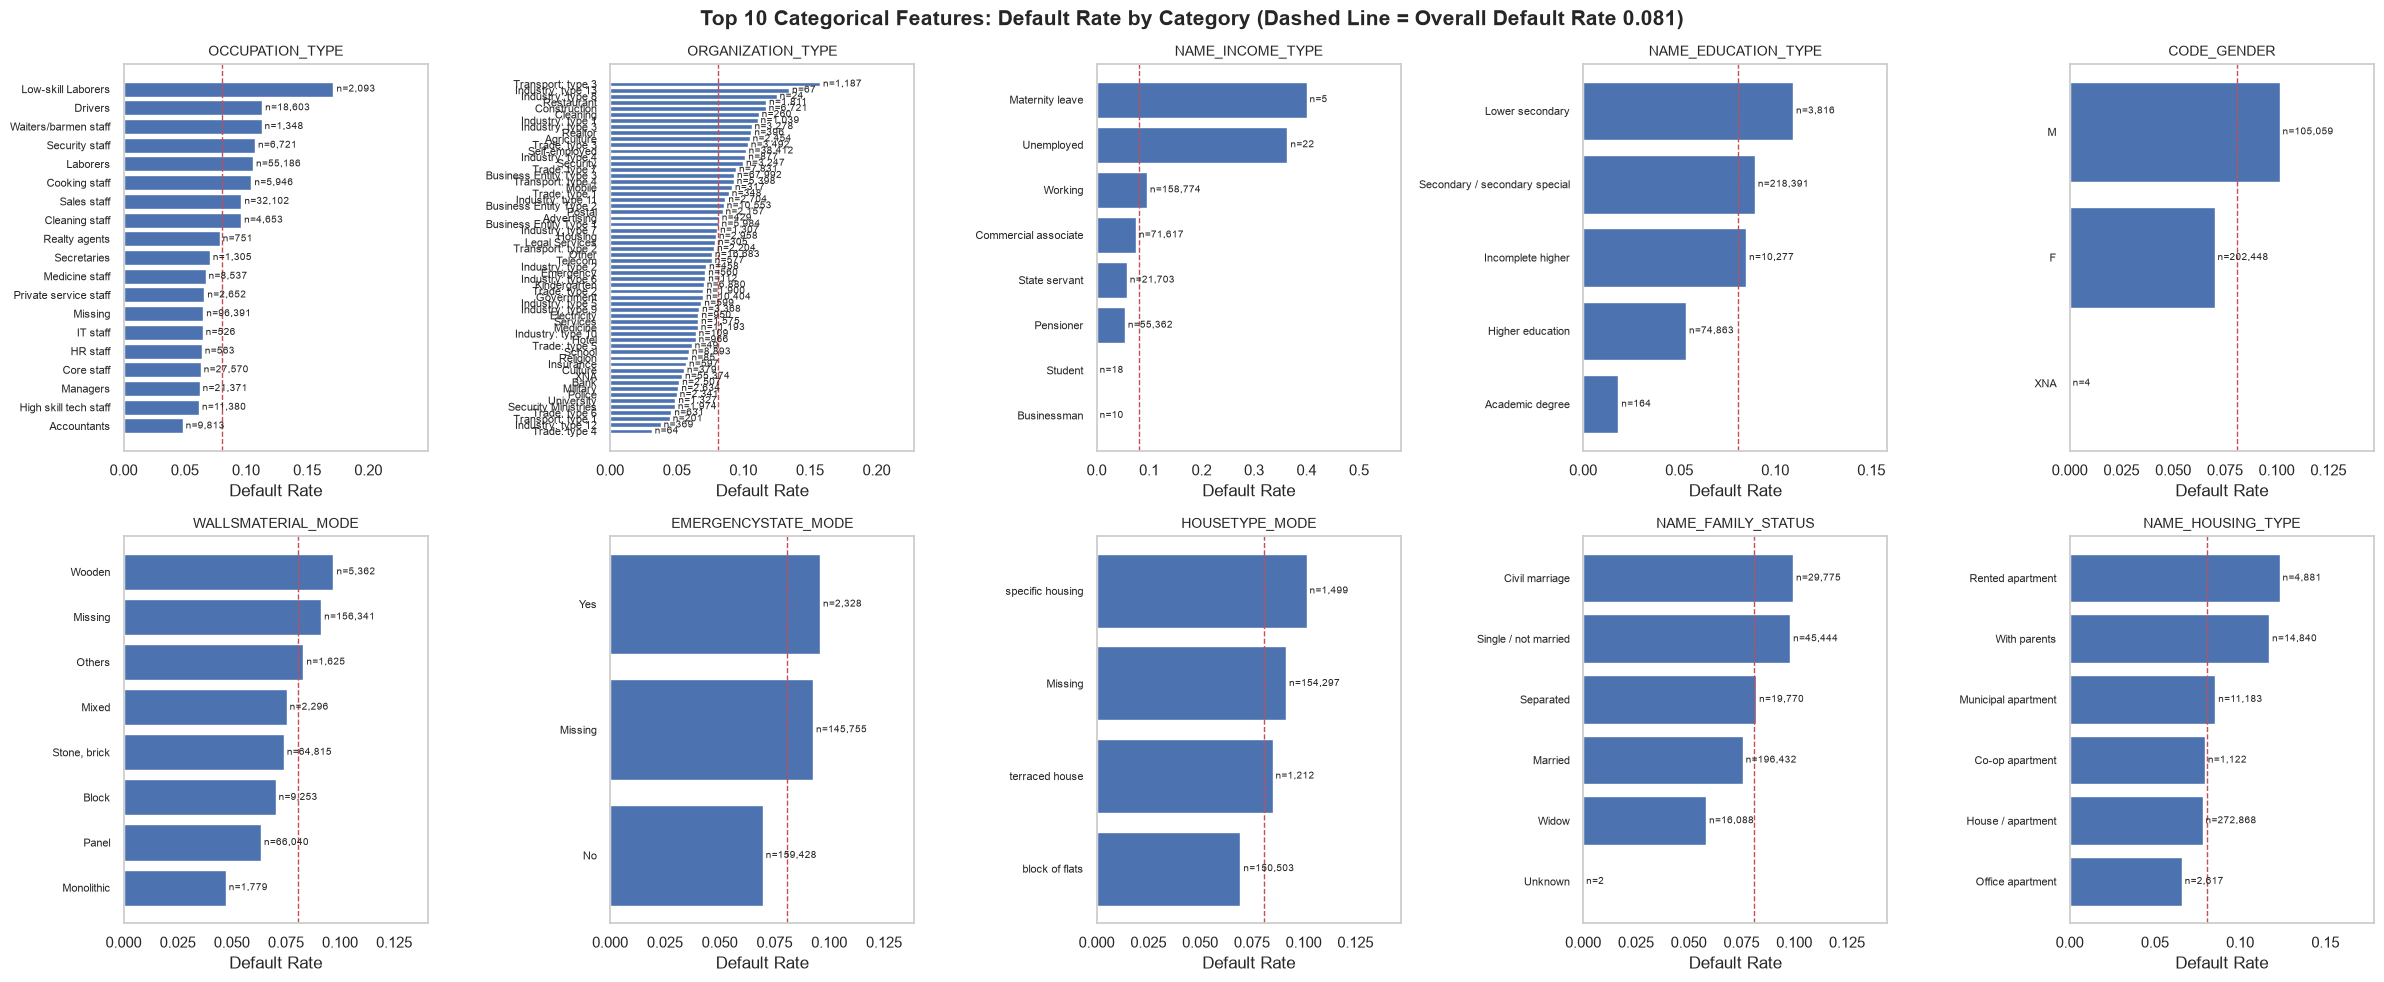

In [12]:


# 1. Identify categorical features
cat_cols = app_train.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

print(f'Total categorical features: {len(cat_cols)}')

# 2. Prepare categorical data
X_cat = app_train[cat_cols].fillna('Missing').astype(str)
y = app_train['TARGET']

# 3. Encode categorical features as integers
encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_encoded = encoder.fit_transform(X_cat)

# 4. Calculate mutual information scores
mi = mutual_info_classif(
    X_encoded,
    y,
    discrete_features=True,
    random_state=42
)

# 5. Rank all categorical features
mi_scores = pd.Series(
    mi,
    index=cat_cols,
    name='Mutual Information'
).sort_values(ascending=False)

# 6. Automatically select the top 10
cats_plot = mi_scores.head(10).index.tolist()

print('\nTop 10 categorical features:')
print(mi_scores.head(10).round(4))

# 7. Plot top 10 features
top10 = mi_scores.head(10).sort_values()

fig, ax = plt.subplots(figsize=(24, 10))

ax.barh(
    top10.index,
    top10.to_numpy(dtype=float),
    color=blue
)
# the information of MI score is above
ax.set_xlabel('Mutual Information Score')
ax.set_ylabel('Categorical Features')
ax.set_title('Top 10 Categorical Features by Mutual Information')

plt.tight_layout()
plt.show()

# 8. Final selected features
#print('\ncats_plot =', cats_plot)

# use the picked top 10 to do the analysis
# Select top 10 categorical features by mutual information
cats_plot = mi_scores.head(10).index.tolist()

# Overall default rate
base = app_train['TARGET'].mean()

# Create 2 rows × 5 columns
fig, axes = plt.subplots(2, 5, figsize=(24, 10))

for ax, c in zip(axes.ravel(), cats_plot):

    # Calculate default rate and sample count by category
    g = (
        app_train
        .groupby(app_train[c].fillna('Missing'))['TARGET']
        .agg(['mean', 'size'])
        .sort_values('mean')
    )

    # Horizontal bar chart
    ax.barh(
        g.index.astype(str).tolist(),
        g['mean'].to_numpy(dtype=float),
        color='#4C72B0'
    )

    # Display sample counts
    for y, (m, n) in enumerate(g[['mean', 'size']].itertuples(
        index=False, name=None
    )):
        ax.text(
            m, y,
            f' n={int(n):,}',
            va='center',
            fontsize=7
        )

    # Overall default rate reference line
    ax.axvline(base, color=red, ls='--', lw=1)

    ax.set_title(c, fontsize=10)
    ax.tick_params(axis='y', labelsize=8)
    ax.set_xlabel('Default Rate')

    # Adjust x-axis range
    ax.set_xlim(0, max(g['mean'].max(), base) * 1.45)

    # Remove background grid
    ax.grid(False)

fig.suptitle(
    f'Top 10 Categorical Features: Default Rate by Category '
    f'(Dashed Line = Overall Default Rate {base:.3f})',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


#### A.10. Auxiliary Tables from Other Tables

- Reference: [A Gentle Introduction (Kaggle)](https://www.kaggle.com/code/willkoehrsen/start-here-a-gentle-introduction)
- We use the links between tables (the keys) to bring in information from the other tables.
- Each auxiliary table has many rows for each applicant, so we must decide how to aggregate them. We need to:
  - check the size of each table,
  - fill in the missing values,
  - choose which aggregated values to add to the training dataset.

In [13]:
aux_tables = ['bureau', 'previous_application', 'POS_CASH_balance', 'installments_payments', 'credit_card_balance']
train_target = app_train.set_index('SK_ID_CURR').TARGET
rows = []
for name in aux_tables:
    ids = pd.read_csv(f'{DATA_DIR}/{name}.csv', usecols=['SK_ID_CURR'])['SK_ID_CURR']
    ncols = len(pd.read_csv(f'{DATA_DIR}/{name}.csv', nrows=0).columns)
    per_client = ids.value_counts()
    has = train_target.index.isin(per_client.index)
    rows.append({'table': name, 'rows': len(ids), 'columns': ncols,
                 'train_coverage': has.mean(),
                 'median_rows_per_client': per_client.median(),
                 'max_rows_per_client': per_client.max(),
                 'default_rate_with_history': train_target[has].mean(),
                 'default_rate_without_history': train_target[~has].mean()})
bb_rows = len(pd.read_csv(f'{DATA_DIR}/bureau_balance.csv', usecols=['SK_ID_BUREAU']))
aux_summary = pd.DataFrame(rows).set_index('table')
display(aux_summary.style.format({'rows': '{:,}', 'train_coverage': '{:.1%}', 'default_rate_with_history': '{:.4f}',
                                  'default_rate_without_history': '{:.4f}', 'median_rows_per_client': '{:.0f}'}))
print(f'bureau_balance: {bb_rows:,} monthly rows, linked to bureau through SK_ID_BUREAU (not directly to SK_ID_CURR).')
del ids, per_client; _ = gc.collect()


,rows,columns,train_coverage,median_rows_per_client,max_rows_per_client,default_rate_with_history,default_rate_without_history
table,,,,,,,
bureau,"1,716,428",17,85.7%,4,116,0.0773,0.1012
previous_application,"1,670,214",37,94.6%,4,77,0.0819,0.0596
POS_CASH_balance,"10,001,358",8,94.1%,22,295,0.0816,0.0666
installments_payments,"13,605,401",8,94.8%,25,372,0.0819,0.0598
credit_card_balance,"3,840,312",23,28.3%,22,192,0.0867,0.0784


bureau_balance: 27,299,925 monthly rows, linked to bureau through SK_ID_BUREAU (not directly to SK_ID_CURR).


Table 6. Largest standardised mean differences (test - train) / std_train


,std_mean_diff,missing_rate_diff
FLAG_EMAIL,0.458,0.000
AMT_REQ_CREDIT_BUREAU_QRT,0.354,-0.011
AMT_REQ_CREDIT_BUREAU_MON,-0.282,-0.011
AMT_GOODS_PRICE,-0.205,-0.001
AMT_CREDIT,-0.204,0.000
FLAG_DOCUMENT_3,0.169,0.000
AMT_ANNUITY,0.160,0.000
AMT_REQ_CREDIT_BUREAU_WEEK,-0.154,-0.011
DAYS_LAST_PHONE_CHANGE,-0.139,-0.000
FLAG_DOCUMENT_16,-0.100,0.000


Table 7. Categorical levels whose share differs most between train and test


,train,test,abs_diff
NAME_CONTRACT_TYPE = Cash loans,0.905,0.991,0.086
NAME_CONTRACT_TYPE = Revolving loans,0.095,0.009,0.086
WEEKDAY_APPR_PROCESS_START = TUESDAY,0.175,0.200,0.025
NAME_FAMILY_STATUS = Married,0.639,0.662,0.024
EMERGENCYSTATE_MODE = No,0.518,0.537,0.019
EMERGENCYSTATE_MODE = Missing,0.474,0.456,0.018
WALLSMATERIAL_MODE = Missing,0.508,0.490,0.018
HOUSETYPE_MODE = Missing,0.502,0.485,0.017


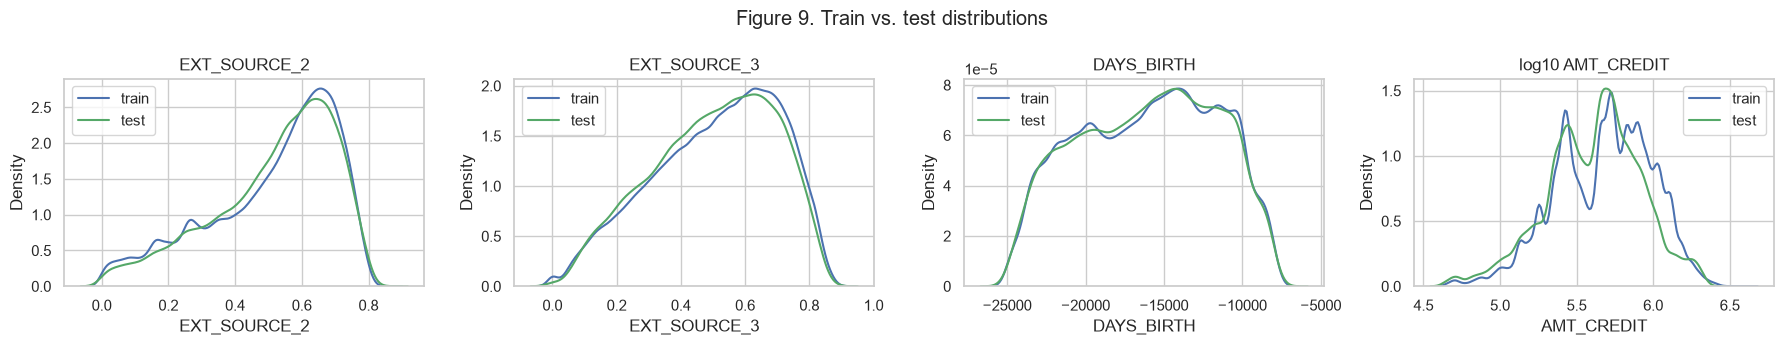

In [14]:
shift_num = app_test.select_dtypes('number').columns.drop('SK_ID_CURR')
smd = ((app_test[shift_num].mean() - app_train[shift_num].mean()) / app_train[shift_num].std()).dropna()
miss_diff = (app_test[shift_num].isna().mean() - app_train[shift_num].isna().mean())
shift_tbl = pd.DataFrame({'std_mean_diff': smd, 'missing_rate_diff': miss_diff}).loc[smd.abs().sort_values(ascending=False).index]
print('Table 6. Largest standardised mean differences (test - train) / std_train')
display(shift_tbl.head(10).round(3))

cat_shift = []
for c in cat_cols_raw:
    a = app_train[c].fillna('Missing').value_counts(normalize=True)
    b = app_test[c].fillna('Missing').value_counts(normalize=True)
    d = pd.concat([a, b], axis=1, keys=['train', 'test']).fillna(0)
    d['abs_diff'] = (d.test - d.train).abs()
    d.index = [f'{c} = {v}' for v in d.index]
    cat_shift.append(d)
cat_shift = pd.concat(cat_shift).sort_values('abs_diff', ascending=False)
print('Table 7. Categorical levels whose share differs most between train and test')
display(cat_shift.head(8).round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, (c, f) in zip(axes, [('EXT_SOURCE_2', None), ('EXT_SOURCE_3', None), ('DAYS_BIRTH', None), ('AMT_CREDIT', np.log10)]):
    for df_, lab, col in [(app_train, 'train', '#4C72B0'), (app_test, 'test', '#55A868')]:
        s = df_[c].dropna(); s = f(s) if f else s
        sns.kdeplot(s, ax=ax, label=lab, color=col, common_norm=False)
    ax.set_title(c if f is None else f'log10 {c}'); ax.legend()
fig.suptitle('Figure 9. Train vs. test distributions'); plt.tight_layout(); plt.show()

In [15]:
age_rate = app_train.TARGET.groupby(pd.cut(-app_train.DAYS_BIRTH / 365.25, bins=range(20, 75, 5)), observed=True).mean()
gender_rate = app_train.groupby('CODE_GENDER').TARGET.mean()
facts = {
    'labelled applications': f'{len(app_train):,}',
    'test applications': f'{len(app_test):,}',
    'default rate': f'{app_train.TARGET.mean():.2%}',
    'imbalance (repaid : default)': f'{vc[0] / vc[1]:.1f} : 1',
    'columns with missing values': f'{len(miss)} of {app_train.shape[1]}',
    'columns > 50% missing': f'{(miss > 0.5).sum()}',
    'DAYS_EMPLOYED placeholder rows': f'{anom.sum():,} ({anom.mean():.1%})',
    'default rate, placeholder vs. other': f'{app_train.TARGET[anom].mean():.2%} vs. {app_train.TARGET[~anom].mean():.2%}',
    'strongest negative correlations': ', '.join(f'{k} ({v:+.3f})' for k, v in corr_t.head(3).items()),
    'strongest positive correlations': ', '.join(f'{k} ({v:+.3f})' for k, v in corr_t.tail(3)[::-1].items()),
    'default rate youngest / oldest age band': f'{age_rate.iloc[0]:.2%} ({age_rate.index[0]}) / {age_rate.iloc[-1]:.2%} ({age_rate.index[-1]})',
    'default rate M / F': f"{gender_rate.get('M', np.nan):.2%} / {gender_rate.get('F', np.nan):.2%}",
    'max AMT_INCOME_TOTAL vs. 99th pct': f"{app_train.AMT_INCOME_TOTAL.max():,.0f} vs. {app_train.AMT_INCOME_TOTAL.quantile(.99):,.0f}",
    'aux-table coverage of applicants': ', '.join(f'{k}: {v:.0%}' for k, v in aux_summary.train_coverage.items()),
    'largest train/test shift': f"{shift_tbl.index[0]} (SMD {shift_tbl.std_mean_diff.iloc[0]:+.2f}); {cat_shift.index[0]} ({cat_shift.train.iloc[0]:.1%} -> {cat_shift.test.iloc[0]:.1%})",
}
print('Table 8. Key EDA figures')
display(pd.Series(facts).to_frame('value'))

Table 8. Key EDA figures


,value
labelled applications,"307,511"
test applications,"48,744"
default rate,8.07%
imbalance (repaid : default),11.4 : 1
columns with missing values,67 of 122
columns > 50% missing,41
DAYS_EMPLOYED placeholder rows,"55,374 (18.0%)"
"default rate, placeholder vs. other",5.40% vs. 8.66%
strongest negative correlations,"EXT_SOURCE_3 (-0.179), EXT_SOURCE_2 (-0.160), ..."
strongest positive correlations,"DAYS_BIRTH (+0.078), DAYS_EMPLOYED (+0.075), R..."


In [16]:


base_rate = app_train.TARGET.mean()
age_years = -app_train.DAYS_BIRTH / 365.25
table8b = (app_train.groupby(pd.cut(age_years, bins=range(20, 75, 5)), observed=True).TARGET
           .agg(n='size', default_rate='mean'))
table8b['lift_vs_overall'] = table8b.default_rate / base_rate
print(f'Table 8b. Default rate by age band (overall rate {base_rate:.2%})')
display(table8b.style.format({'n': '{:,}', 'default_rate': '{:.2%}', 'lift_vs_overall': '{:.2f}x'}))

# Table 8c: default rate per categorical level; levels below the minimum size are hidden as too noisy
min_level_share = 0.005
cat_signal = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE',
              'NAME_HOUSING_TYPE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS']
parts = []
for c in cat_signal:
    g = app_train.groupby(app_train[c].fillna('Missing')).TARGET.agg(n='size', default_rate='mean')
    g = g[g.n >= min_level_share * len(app_train)].sort_values('default_rate', ascending=False)
    g.index = pd.MultiIndex.from_product([[c], g.index], names=['feature', 'level'])
    parts.append(g)
table8c = pd.concat(parts)
table8c['lift_vs_overall'] = table8c.default_rate / base_rate
print(f'Table 8c. Default rate by categorical level (levels with >= {min_level_share:.1%} of applications)')
display(table8c.style.format({'n': '{:,}', 'default_rate': '{:.2%}', 'lift_vs_overall': '{:.2f}x'})
        .background_gradient(subset=['lift_vs_overall'], cmap='RdBu_r', vmin=0.5, vmax=1.5))

Table 8b. Default rate by age band (overall rate 8.07%)


,n,default_rate,lift_vs_overall
DAYS_BIRTH,,,
"(20, 25]","12,233",12.29%,1.52x
"(25, 30]","32,953",11.13%,1.38x
"(30, 35]","39,476",10.27%,1.27x
"(35, 40]","42,873",8.96%,1.11x
"(40, 45]","41,388",7.83%,0.97x
"(45, 50]","35,193",7.42%,0.92x
"(50, 55]","34,997",6.67%,0.83x
"(55, 60]","33,112",5.54%,0.69x
"(60, 65]","27,410",5.28%,0.65x


Table 8c. Default rate by categorical level (levels with >= 0.5% of applications)


## A.10. Initial Findings and Hypotheses

**Imbalance.** About 8.1% of applications are defaults (24,825 / 307,511; see A.2 Target Balance).

**Missing data is common.** The largest group is the ~47 normalized building features (`*_AVG`, `*_MODE`, `*_MEDI`). They are 50–70% missing, and they are missing *together*. `EXT_SOURCE_1` (~56%) and `OWN_CAR_AGE` (~66%) are also mostly missing. The missingness is not random: applicants with no `EXT_SOURCE_1`/`EXT_SOURCE_3`, or with no building information, default more often.
- **Hypothesis:** impute the missing values (mean or median) and add a "missing" flag, instead of dropping the data. (See A.3 Missing Values Evaluation.)

**Anomalies.** `DAYS_EMPLOYED = 365243` appears in 18% of rows. (See A.5 Anomaly Detection and Analysis.)

**Strongest raw signals.** The three external scores (`EXT_SOURCE_1/2/3`) are the most predictive features, and their density curves for defaulters and non-defaulters are clearly different. Younger applicants default more: 12.29% in the 20–25 age group vs 3.66% in the 60–70 age group.

**Redundancy.** Many numeric pairs have |r| > 0.95 (for example, `AMT_CREDIT` and `AMT_GOODS_PRICE`). Highly correlated inputs make logistic regression coefficients unstable and make SVM training more costly.

**Auxiliary tables.** Coverage is very different between tables. Most applicants have bureau and previous-application records, but only 28.3% have credit-card history.
- **Hypotheses:**
  1. Repayment behavior (for example, late or partial payments, past-due amounts) helps predict default.
  2. Missing credit history is also informative. We fill record counts with 0 and flag the missing pattern.

# (b) Data Preprocessing and Cleaning

| Step | What | Fitted on |
|---|---|---|
| b.1 | Stratified 80/20 split of `application_train` | — |
| b.2 | Row-wise cleaning and domain features on the application table | Nothing (row-wise formulas only) |
| b.3 | Aggregate the six auxiliary tables to one row per `SK_ID_CURR`, then left-join | Rare-category vocabularies: training clients only |
| b.4 | Drop very sparse and near-constant columns; add missing indicators (no duplicates) | Training split |
| b.5 | Median imputation | Training split |
| b.6 | Clip to the 0.1st and 99.9th percentiles; apply `log1p` to skewed non-negative columns | Training split |
| b.7 | Drop one column from each pair with \|r\| > 0.98 | Training split |
| b.8 | Standardize numeric features; one-hot encode categorical features (rare levels grouped) | Training split |

## b.1 Stratified Train/Validation Split

We make the split first, so every later fitted step uses only the training rows.

In [17]:
# split the dataset
"""
tr_idx contains row positioins, not SK_ID_CURR, it is a row index not the ID
train_ids is unique among different files
"""
y_all = app_train.TARGET.values.astype(np.int8) # save memory 
tr_idx, va_idx = train_test_split(np.arange(len(app_train)), test_size=CONFIG['val_size'], stratify=y_all, random_state=CONFIG['seed'])
train_ids = set(app_train.SK_ID_CURR.values[tr_idx])

print(f'train {len(tr_idx):,} rows, default rate {y_all[tr_idx].mean():.4f}')
print(f'valid {len(va_idx):,} rows, default rate {y_all[va_idx].mean():.4f}')

train 246,008 rows, default rate 0.0807
valid 61,503 rows, default rate 0.0807


## b.2 Application table: cleaning and domain features
- DAYS_EMPLOYED = 365243 change to NaN + flag DAYS_EMPLOYED_ANOM
- CODE_GENDER = "XNA" $\rightarrow$ missing
- Affordable ratios: credit / income, annuity / income, goods / credit, income / family member
- external-score mean, min, max, std et al.
- Number of documents provided.

In [18]:
def engineer_application(app):
    #function creates 13 new features:
    df = app.copy() # create an individual data copy
    df['DAYS_EMPLOYED_ANOM'] = (df.DAYS_EMPLOYED==365243).astype(np.int8)
    df['DAYS_EMPLOYED'] = df.DAYS_EMPLOYED.where(df.DAYS_EMPLOYED != 365243)
    df['CODE_GENDER'] = df.CODE_GENDER.where(df.CODE_GENDER != 'XNA')

    df['CREDIT_INCOME_RATIO'] = df.AMT_CREDIT / df.AMT_INCOME_TOTAL
    df['ANNUITY_INCOME_RATIO'] = df.AMT_ANNUITY / df.AMT_INCOME_TOTAL
    df['ANNUITY_CREDIT_RATIO'] = df.AMT_ANNUITY / df.AMT_CREDIT
    df['GOODS_CREDIT_RATIO'] = df.AMT_GOODS_PRICE / df.AMT_CREDIT
    df['INCOME_PER_PERSON'] = df.AMT_INCOME_TOTAL / df.CNT_FAM_MEMBERS
    df['EMPLOYED_AGE_RATIO'] = df.DAYS_EMPLOYED / df.DAYS_BIRTH

    ext = df[['EXT_SOURCE_1', 'EXT_SOURCE_2','EXT_SOURCE_3']]
    df['EXT_MEAN'] = ext.mean(axis=1)
    df['EXT_MIN'] = ext.min(axis=1)
    df['EXT_MAX'] = ext.max(axis=1)
    df['EXT_STD'] = ext.std(axis=1)
    df['EXT_PROD'] = ext.prod(axis=1)
    df['EXT_N_MISSING'] = ext.isna().sum(axis=1).astype(np.int8)

    doc_cols = [c for c in df.columns if c.startswith('FLAG_DOCUMENT_')]
    df['doc_count'] = df[doc_cols].sum(axis=1).astype(np.int8)

    return df


## b.3 Combine the auxiliary tables
- bureau_balance $\rightarrow$ bureau $\rightarrow$ applicants
- previous_application. 365243 in the DAYS_columns  $\rightarrow$ NaN. 
- installation_payments
- POS_CASH_balance
- credit_card_balance: balance, limit, utilisation, drawing, payment vs requirement minimum, days past due, overall and over the last 12 months

**Leakage.** The aggregates use only each applicant's own history and never the target, so they cannot leak information between applicants.

In [19]:
def sanitize(name):
    return re.sub(r'[^A-Za-z0-9]+', '_', str(name)).strip('_').upper()

def clean_inf(df):
    num = df.select_dtypes('number').columns
    df[num] = df[num].replace([np.inf, -np.inf], np.nan)
    return df

def num_aggs(df, spec, prefix, key='SK_ID_CURR'):
    g = df.groupby(key).agg(spec)
    g.columns = [f'{prefix}_{c}_{s}'.upper() for c, s in g.columns]
    return g

def lump_rare(df, cols, ref_mask, min_share=0.01):
    
    for c in cols:
        s = df[c].astype(object).where(df[c].notna(), 'Missing')
        share = s[ref_mask].value_counts(normalize=True)
        df[c] = s.where(s.isin(share[share >= min_share].index), 'Other')
    return df

def cat_shares(df, cols, prefix, key='SK_ID_CURR'):
    d = pd.get_dummies(df[cols].astype(str), dtype=np.float32)
    d[key] = df[key].values
    g = d.groupby(key).mean()
    g.columns = [f'{prefix}_{sanitize(c)}_SHARE' for c in g.columns]
    return g





In [20]:
def bureau_features(train_ids):
    bb = load('bureau_balance', cat=True)
    late = bb.STATUS.isin(['1', '2', '3', '4', '5'])
    bb['DPD'] = late.astype(np.float32)
    bb['DPD30'] = bb.STATUS.isin(['2', '3', '4', '5']).astype(np.float32)
    bb['UNKNOWN'] = (bb.STATUS == 'X').astype(np.float32)
    bb['DPD_LAST12'] = np.where(bb.MONTHS_BALANCE >= -12, bb.DPD, np.nan).astype(np.float32)
    bb_agg = bb.groupby('SK_ID_BUREAU').agg(BB_MONTHS=('MONTHS_BALANCE', 'size'),
                                             BB_DPD_SHARE=('DPD', 'mean'),
                                             BB_DPD30_EVER=('DPD30', 'max'),
                                             BB_UNKNOWN_SHARE=('UNKNOWN', 'mean'),
                                             BB_DPD_LAST12=('DPD_LAST12', 'max'))
    del bb, late; gc.collect()

    bu = load('bureau', cat=True)
    bu = bu.merge(bb_agg, left_on='SK_ID_BUREAU', right_index=True, how='left')
    del bb_agg; gc.collect()
    bu['DEBT_CREDIT_RATIO'] = bu.AMT_CREDIT_SUM_DEBT / bu.AMT_CREDIT_SUM
    bu['CREDIT_DURATION'] = bu.DAYS_CREDIT_ENDDATE - bu.DAYS_CREDIT
    bu['ENDDATE_DIFF'] = bu.DAYS_ENDDATE_FACT - bu.DAYS_CREDIT_ENDDATE   # >0: closed later than planned
    bu = clean_inf(bu)

    agg = num_aggs(bu, {
        'DAYS_CREDIT': ['min', 'max', 'mean'],
        'DAYS_CREDIT_ENDDATE': ['max', 'mean'],
        'DAYS_CREDIT_UPDATE': ['mean'],
        'CREDIT_DAY_OVERDUE': ['max', 'mean'],
        'AMT_CREDIT_MAX_OVERDUE': ['max', 'mean'],
        'AMT_CREDIT_SUM': ['sum', 'mean', 'max'],
        'AMT_CREDIT_SUM_DEBT': ['sum', 'mean'],
        'AMT_CREDIT_SUM_OVERDUE': ['sum', 'max'],
        'AMT_CREDIT_SUM_LIMIT': ['sum', 'mean'],
        'CNT_CREDIT_PROLONG': ['sum'],
        'DEBT_CREDIT_RATIO': ['mean', 'max'],
        'CREDIT_DURATION': ['mean'],
        'ENDDATE_DIFF': ['mean'],
        'BB_MONTHS': ['mean', 'sum'],
        'BB_DPD_SHARE': ['mean', 'max'],
        'BB_DPD30_EVER': ['mean', 'max'],
        'BB_UNKNOWN_SHARE': ['mean'],
        'BB_DPD_LAST12': ['mean', 'max'],
    }, 'BURO')
    agg['BURO_COUNT'] = bu.groupby('SK_ID_CURR').size()

    ref = bu.SK_ID_CURR.isin(train_ids)
    bu = lump_rare(bu, ['CREDIT_ACTIVE', 'CREDIT_TYPE'], ref)
    agg = agg.join(cat_shares(bu, ['CREDIT_ACTIVE', 'CREDIT_TYPE'], 'BURO'))

    act = bu[bu.CREDIT_ACTIVE == 'Active']
    agg = agg.join(num_aggs(act, {'AMT_CREDIT_SUM': ['sum'], 'AMT_CREDIT_SUM_DEBT': ['sum'],
                                  'AMT_CREDIT_SUM_OVERDUE': ['sum'], 'DAYS_CREDIT_ENDDATE': ['max', 'mean'],
                                  'DEBT_CREDIT_RATIO': ['mean']}, 'BURO_ACT'))
    agg['BURO_ACT_COUNT'] = act.groupby('SK_ID_CURR').size()
    agg['BURO_ACT_DEBT_CREDIT_RATIO'] = agg.BURO_ACT_AMT_CREDIT_SUM_DEBT_SUM / agg.BURO_ACT_AMT_CREDIT_SUM_SUM

    clo = bu[bu.CREDIT_ACTIVE == 'Closed']
    agg = agg.join(num_aggs(clo, {'DAYS_CREDIT': ['max'], 'DAYS_ENDDATE_FACT': ['max'],
                                  'AMT_CREDIT_SUM': ['mean']}, 'BURO_CLO'))
    agg['BURO_CLO_COUNT'] = clo.groupby('SK_ID_CURR').size()
    del bu, act, clo; gc.collect()
    return clean_inf(agg).astype(np.float32)

In [21]:
def previous_features(train_ids):
    pa = load('previous_application', cat=True)
    for c in ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION']:
        pa[c] = pa[c].where(pa[c] != 365243)
    pa['APP_CREDIT_RATIO'] = pa.AMT_APPLICATION / pa.AMT_CREDIT
    pa['ANNUITY_CREDIT_RATIO'] = pa.AMT_ANNUITY / pa.AMT_CREDIT
    pa['END_VS_PLANNED'] = pa.DAYS_LAST_DUE - pa.DAYS_LAST_DUE_1ST_VERSION   # <0: finished early
    pa['APPROVED'] = (pa.NAME_CONTRACT_STATUS == 'Approved').astype(np.float32)
    pa['REFUSED'] = (pa.NAME_CONTRACT_STATUS == 'Refused').astype(np.float32)
    pa = clean_inf(pa)

    agg = num_aggs(pa, {
        'AMT_ANNUITY': ['mean', 'max'],
        'AMT_APPLICATION': ['mean', 'max'],
        'AMT_CREDIT': ['mean', 'max', 'sum'],
        'APP_CREDIT_RATIO': ['mean', 'min', 'max'],
        'ANNUITY_CREDIT_RATIO': ['mean'],
        'RATE_DOWN_PAYMENT': ['mean', 'max'],
        'DAYS_DECISION': ['min', 'max', 'mean'],
        'CNT_PAYMENT': ['mean', 'sum'],
        'END_VS_PLANNED': ['mean'],
        'APPROVED': ['sum', 'mean'],
        'REFUSED': ['sum', 'mean'],
    }, 'PREV')
    agg['PREV_COUNT'] = pa.groupby('SK_ID_CURR').size()

    cats = ['NAME_CONTRACT_TYPE', 'NAME_YIELD_GROUP', 'NAME_CLIENT_TYPE', 'CODE_REJECT_REASON',
            'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE']
    pa = lump_rare(pa, cats, pa.SK_ID_CURR.isin(train_ids))
    agg = agg.join(cat_shares(pa, cats, 'PREV'))

    agg = agg.join(num_aggs(pa[pa.APPROVED == 1], {
        'AMT_CREDIT': ['mean', 'max'], 'APP_CREDIT_RATIO': ['mean'], 'DAYS_DECISION': ['max'],
        'DAYS_TERMINATION': ['max'], 'CNT_PAYMENT': ['mean']}, 'PREV_APPR'))
    agg = agg.join(num_aggs(pa[pa.REFUSED == 1], {
        'AMT_APPLICATION': ['mean', 'max'], 'DAYS_DECISION': ['max']}, 'PREV_REF'))
    del pa; gc.collect()
    return clean_inf(agg).astype(np.float32)

In [22]:
def pos_features():
    pos = load('POS_CASH_balance', cat=True)
    pos['LATE'] = (pos.SK_DPD > 0).astype(np.float32)
    pos['COMPLETED'] = (pos.NAME_CONTRACT_STATUS == 'Completed').astype(np.float32)
    agg = num_aggs(pos, {'MONTHS_BALANCE': ['min', 'size'], 'SK_DPD': ['max', 'mean'],
                         'SK_DPD_DEF': ['max', 'mean'], 'LATE': ['mean'],
                         'CNT_INSTALMENT': ['mean'], 'CNT_INSTALMENT_FUTURE': ['mean']}, 'POS')
    agg['POS_N_LOANS'] = pos.groupby('SK_ID_CURR').SK_ID_PREV.nunique()
    last = pos.loc[pos.groupby('SK_ID_PREV').MONTHS_BALANCE.idxmax()]       # latest month of each loan
    agg = agg.join(num_aggs(last, {'CNT_INSTALMENT_FUTURE': ['sum', 'mean'], 'COMPLETED': ['mean']}, 'POS_LAST'))
    agg = agg.join(num_aggs(pos[pos.MONTHS_BALANCE >= -12], {'LATE': ['mean'], 'SK_DPD': ['max']}, 'POS_RECENT'))
    del pos, last; gc.collect()
    return clean_inf(agg).astype(np.float32)

def installments_features():
    ins = load('installments_payments')
    keys = ['SK_ID_CURR', 'SK_ID_PREV', 'NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER']
    n_raw = len(ins)
    ins = ins.groupby(keys, sort=False).agg(DAYS_INSTALMENT=('DAYS_INSTALMENT', 'min'),
                                            AMT_INSTALMENT=('AMT_INSTALMENT', 'max'),
                                            DAYS_ENTRY_PAYMENT=('DAYS_ENTRY_PAYMENT', 'max'),
                                            AMT_PAYMENT=('AMT_PAYMENT', 'sum')).reset_index()
    print(f'  installments: {n_raw:,} payment rows -> {len(ins):,} instalments')
    ins['DPD'] = (ins.DAYS_ENTRY_PAYMENT - ins.DAYS_INSTALMENT).clip(lower=0)
    ins['DBD'] = (ins.DAYS_INSTALMENT - ins.DAYS_ENTRY_PAYMENT).clip(lower=0)
    ins['LATE'] = (ins.DPD > 0).astype(np.float32)
    ins['PAYMENT_DIFF'] = ins.AMT_INSTALMENT - ins.AMT_PAYMENT
    ins['PAYMENT_RATIO'] = ins.AMT_PAYMENT / ins.AMT_INSTALMENT
    ins['UNDERPAID'] = (ins.PAYMENT_DIFF > 1).astype(np.float32)
    ins = clean_inf(ins)
    agg = num_aggs(ins, {'DPD': ['max', 'mean', 'sum'], 'DBD': ['max', 'mean'], 'LATE': ['mean', 'sum'],
                         'PAYMENT_DIFF': ['mean', 'max', 'sum'], 'PAYMENT_RATIO': ['mean', 'min'],
                         'UNDERPAID': ['mean'], 'AMT_INSTALMENT': ['size', 'sum'],
                         'AMT_PAYMENT': ['sum', 'mean']}, 'INS')
    agg['INS_N_LOANS'] = ins.groupby('SK_ID_CURR').SK_ID_PREV.nunique()
    agg = agg.join(num_aggs(ins[ins.DAYS_INSTALMENT >= -365], {
        'LATE': ['mean'], 'DPD': ['mean', 'max'], 'PAYMENT_RATIO': ['mean'], 'UNDERPAID': ['mean']}, 'INS_RECENT'))
    del ins; gc.collect()
    return clean_inf(agg).astype(np.float32)

def credit_card_features():
    cc = load('credit_card_balance', cat=True)
    lim = cc.AMT_CREDIT_LIMIT_ACTUAL.where(cc.AMT_CREDIT_LIMIT_ACTUAL > 0)
    cc['UTILIZATION'] = cc.AMT_BALANCE / lim
    cc['DRAWING_RATIO'] = cc.AMT_DRAWINGS_CURRENT / lim
    cc['PAY_MIN_RATIO'] = cc.AMT_PAYMENT_TOTAL_CURRENT / cc.AMT_INST_MIN_REGULARITY.where(cc.AMT_INST_MIN_REGULARITY > 0)
    cc['LATE'] = (cc.SK_DPD > 0).astype(np.float32)
    cc = clean_inf(cc)
    agg = num_aggs(cc, {'MONTHS_BALANCE': ['size', 'min'], 'AMT_BALANCE': ['mean', 'max'],
                        'AMT_CREDIT_LIMIT_ACTUAL': ['mean', 'max'], 'UTILIZATION': ['mean', 'max'],
                        'DRAWING_RATIO': ['mean'], 'AMT_DRAWINGS_CURRENT': ['mean', 'max'],
                        'CNT_DRAWINGS_CURRENT': ['mean', 'max'], 'AMT_PAYMENT_TOTAL_CURRENT': ['mean'],
                        'PAY_MIN_RATIO': ['mean', 'min'], 'SK_DPD': ['max', 'mean'], 'LATE': ['mean']}, 'CC')
    agg = agg.join(num_aggs(cc[cc.MONTHS_BALANCE >= -12], {
        'UTILIZATION': ['mean'], 'LATE': ['mean'], 'AMT_BALANCE': ['mean']}, 'CC_RECENT'))
    del cc; gc.collect()
    return clean_inf(agg).astype(np.float32)

In [23]:
aggs = {}
for name, fn in [('bureau', lambda: bureau_features(train_ids)),
                 ('previous', lambda: previous_features(train_ids)),
                 ('pos_cash', pos_features),
                 ('installments', installments_features),
                 ('credit_card', credit_card_features)]:
    t0 = time.time()
    aggs[name] = fn()
    gc.collect()
    print(f'{name:13s} -> {aggs[name].shape[0]:>7,} clients x {aggs[name].shape[1]:>3} features  ({time.time() - t0:.0f}s)')

bureau        -> 305,811 clients x  54 features  (13s)
previous      -> 338,857 clients x  62 features  (10s)
pos_cash      -> 337,252 clients x  15 features  (9s)
  installments: 13,605,401 payment rows -> 12,951,918 instalments
installments  -> 339,587 clients x  23 features  (16s)
credit_card   -> 103,558 clients x  22 features  (6s)


In [24]:
COUNT_SUFFIXES = ('_COUNT', '_SIZE', '_N_LOANS', 'APPROVED_SUM', 'REFUSED_SUM')

def build_features(app):
    df = engineer_application(app)
    for a in aggs.values():
        df = df.merge(a, left_on='SK_ID_CURR', right_index=True, how='left')
    cnt = [c for c in df.columns if c.endswith(COUNT_SUFFIXES)]
    df[cnt] = df[cnt].fillna(0)                       # no record = zero records
    # cross-table features
    df['BURO_ACT_DEBT_TO_INCOME'] = df.BURO_ACT_AMT_CREDIT_SUM_DEBT_SUM / df.AMT_INCOME_TOTAL
    df['INS_PAYMENT_TO_INCOME'] = df.INS_AMT_PAYMENT_MEAN / df.AMT_INCOME_TOTAL
    df['CC_LIMIT_TO_INCOME'] = df.CC_AMT_CREDIT_LIMIT_ACTUAL_MAX / df.AMT_INCOME_TOTAL
    return clean_inf(df)

full_train = build_features(app_train)
full_test = build_features(app_test)
assert list(full_train.columns.drop('TARGET')) == list(full_test.columns)
assert len(full_train) == len(app_train) and len(full_test) == len(app_test)

X_tr_df = full_train.iloc[tr_idx].drop(columns='TARGET').reset_index(drop=True)
X_va_df = full_train.iloc[va_idx].drop(columns='TARGET').reset_index(drop=True)
X_te_df = full_test.reset_index(drop=True)
y_train, y_val = y_all[tr_idx], y_all[va_idx]
test_ids = X_te_df.SK_ID_CURR.values
print(f'combined feature set: {X_tr_df.shape[1] - 1} columns (before cleaning), train {X_tr_df.shape}, test {X_te_df.shape}')
del full_train, full_test, aggs; _ = gc.collect()

combined feature set: 313 columns (before cleaning), train (246008, 314), test (48744, 314)


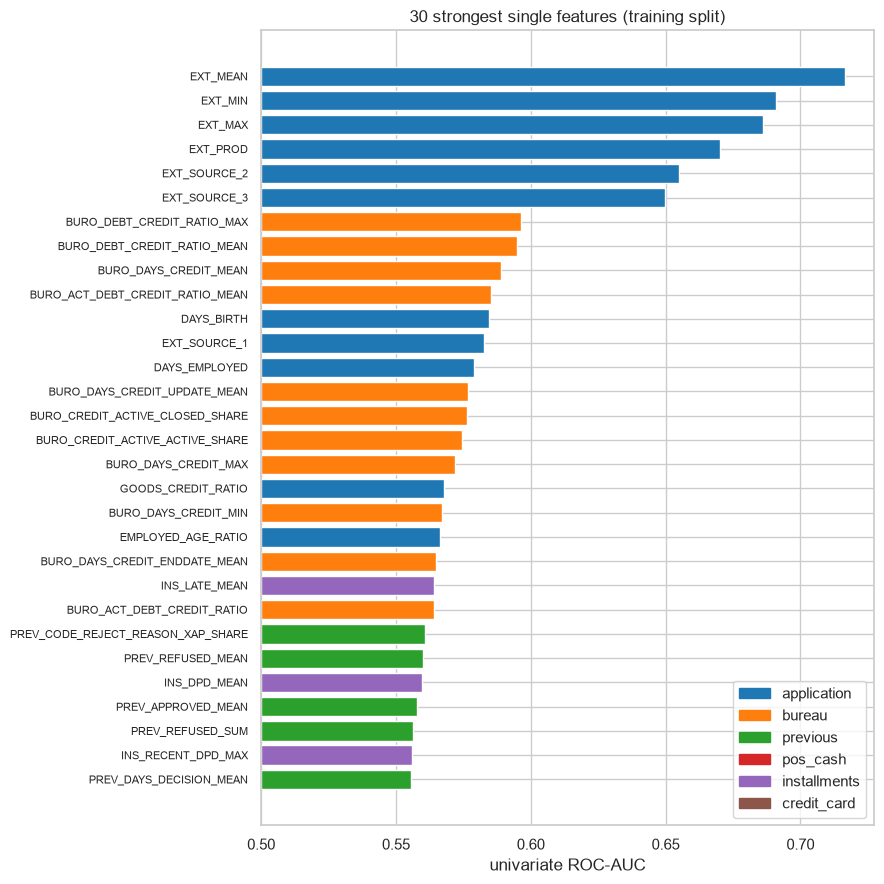

,size,max,mean
source,,,
application,118,0.716,0.526
bureau,55,0.596,0.531
credit_card,23,0.552,0.526
installments,24,0.564,0.535
pos_cash,15,0.555,0.522
previous,62,0.561,0.525


In [25]:
def source(c):
    for p, s in [('BURO', 'bureau'), ('PREV', 'previous'), ('POS', 'pos_cash'), ('INS', 'installments'), ('CC', 'credit_card')]:
        if c.startswith(p + '_'):
            return s
    return 'application'

uni = {}
for c in X_tr_df.select_dtypes('number').columns.drop('SK_ID_CURR'):
    s = X_tr_df[c]
    if s.nunique() > 1:
        a = roc_auc_score(y_train, s.fillna(s.median()))
        uni[c] = max(a, 1 - a)
uni = pd.Series(uni).sort_values(ascending=False)
src = uni.index.map(source)

top = uni.head(30)[::-1]
palette = dict(zip(['application', 'bureau', 'previous', 'pos_cash', 'installments', 'credit_card'], sns.color_palette('tab10')))
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(top.index, top.values - 0.5, left=0.5, color=[palette[source(c)] for c in top.index])
ax.set_xlabel('univariate ROC-AUC'); ax.tick_params(axis='y', labelsize=8)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=v) for v in palette.values()], labels=palette.keys(), loc='lower right')
ax.set_title('30 strongest single features (training split)'); plt.tight_layout(); plt.show()
display(pd.DataFrame({'auc': uni, 'source': src}).groupby('source').auc.agg(['size', 'max', 'mean']).round(3))

## b.4- b.8 Train-fitted preprocessing
The class below is fitted on the training split only and then used to transform validation and test.
* **b.4 Column filtering and missing indicators.** Numeric columns more than 80% missing in train, or whose
  most frequent value covers more than 99.5% of train rows, carry almost no information and are dropped.
  For every remaining numeric column with at least 5% missing, a 0/1 `_ISNA` indicator is created, but
  only one indicator per distinct missing pattern (the ~47 building columns, or all features from one
  auxiliary table, share the same pattern, so a single flag represents each block).
* **b.5 Imputation.** Numeric NaN → training median (robust to the heavy tails seen in a.4). Categorical
  NaN → its own level `"Missing"`, since a.3 showed that missingness is informative.
* **b.6 Outliers and skew.** Values are clipped to the training 0.1st/99.9th percentiles (this tames the
  117-million income without removing rows). Non-negative, non-binary columns with |skew| > 2 get `log1p`.
  Both matter for Logistic Regression and the SVM, and are harmless monotone changes for the tree.
* **b.7 Redundancy.** Columns are scanned in order and a column is dropped if |r| > 0.98 with one already kept.
* **b.8 Scaling and encoding.** Numeric features are standardised (zero mean, unit variance on train),
  which is required for the regularised Logistic Regression and the RBF/linear SVM. Categoricals are
  one-hot encoded; levels seen in fewer than 0.5% of training rows are merged into an "infrequent" level,
  unseen levels at validation/test time map to it as well, and binary columns keep a single dummy.

In [26]:
class HomeCreditPreprocessor:
    def __init__(self, max_missing=0.80, max_mode_share=0.995, indicator_min_missing=0.05,
                 clip_q=(0.001, 0.999), skew_threshold=2.0, corr_threshold=0.98, min_cat_freq=0.005):
        self.max_missing, self.max_mode_share = max_missing, max_mode_share
        self.indicator_min_missing, self.clip_q = indicator_min_missing, clip_q
        self.skew_threshold, self.corr_threshold, self.min_cat_freq = skew_threshold, corr_threshold, min_cat_freq

    def _split(self, df):
        df = df.drop(columns=['SK_ID_CURR', 'TARGET'], errors='ignore')
        cat = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
        return df.drop(columns=cat).astype(np.float32), df[cat]

    @staticmethod
    def _cat_prep(cat):
        return cat.astype(object).where(cat.notna(), 'Missing').astype(str)

    def fit(self, df):
        num, cat = self._split(df)
        self.cat_cols_ = cat.columns.tolist()
        self.report_ = {'numeric_in': num.shape[1], 'categorical_in': cat.shape[1]}

        miss = num.isna().mean()
        self.drop_missing_ = miss.index[miss > self.max_missing].tolist()
        num = num.drop(columns=self.drop_missing_)
        mode_share = num.apply(lambda s: s.value_counts(dropna=False, normalize=True).iloc[0])
        self.drop_constant_ = mode_share.index[mode_share > self.max_mode_share].tolist()
        num = num.drop(columns=self.drop_constant_)
        self.num_in_ = num.columns.tolist()

        # one missing-indicator per distinct missing pattern
        miss = num.isna().mean()
        seen, self.indicator_cols_ = set(), []
        for c in miss.index[miss >= self.indicator_min_missing]:
            key = hash(num[c].isna().values.tobytes())
            if key not in seen:
                seen.add(key); self.indicator_cols_.append(c)

        self.medians_ = num.median()
        num = num.fillna(self.medians_)
        self.lo_, self.hi_ = num.quantile(self.clip_q[0]), num.quantile(self.clip_q[1])
        num = num.clip(self.lo_, self.hi_, axis=1)

        skew, nuniq = num.skew(), num.nunique()
        self.log_cols_ = [c for c in num.columns
                          if num[c].min() >= 0 and nuniq[c] > 2 and abs(skew[c]) > self.skew_threshold]
        num[self.log_cols_] = np.log1p(num[self.log_cols_])

        std = num.std()
        num = num.loc[:, std > 0]
        Z = ((num - num.mean()) / num.std()).values.astype(np.float32)
        C = np.abs(Z.T @ Z) / (len(Z) - 1)
        del Z
        keep = []
        for j in range(C.shape[0]):
            if not keep or C[j, keep].max() <= self.corr_threshold:
                keep.append(j)
        self.num_out_ = num.columns[keep].tolist()
        self.drop_corr_ = [c for c in num.columns if c not in self.num_out_]

        self.scaler_ = StandardScaler().fit(num[self.num_out_])
        self.ohe_ = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=self.min_cat_freq,
                                  drop='if_binary', sparse_output=False, dtype=np.float32)
        self.ohe_.fit(self._cat_prep(cat))

        self.feature_names_ = (self.num_out_ + [f'{c}_ISNA' for c in self.indicator_cols_]
                               + list(self.ohe_.get_feature_names_out(self.cat_cols_)))
        self.report_.update({'dropped_too_missing': len(self.drop_missing_),
                             'dropped_near_constant': len(self.drop_constant_),
                             'missing_indicators': len(self.indicator_cols_),
                             'log_transformed': len(self.log_cols_),
                             'dropped_collinear': len(self.drop_corr_),
                             'numeric_out': len(self.num_out_),
                             'one_hot_out': len(self.feature_names_) - len(self.num_out_) - len(self.indicator_cols_),
                             'total_features': len(self.feature_names_)})
        return self

    def transform(self, df):
        num, cat = self._split(df)
        num = num[self.num_in_].replace([np.inf, -np.inf], np.nan)
        ind = num[self.indicator_cols_].isna().values.astype(np.float32)
        num = num.fillna(self.medians_).clip(self.lo_, self.hi_, axis=1)
        num[self.log_cols_] = np.log1p(num[self.log_cols_])
        Xn = self.scaler_.transform(num[self.num_out_]).astype(np.float32)
        Xc = self.ohe_.transform(self._cat_prep(cat[self.cat_cols_]))
        return np.hstack([Xn, ind, Xc]).astype(np.float32)

In [27]:
t0 = time.time()
prep = HomeCreditPreprocessor(**CONFIG['prep']).fit(X_tr_df)          # <- training split only
X_train = prep.transform(X_tr_df)
X_val   = prep.transform(X_va_df)
X_test  = prep.transform(X_te_df)
print(f'fit + transform: {time.time() - t0:.0f}s')
display(pd.Series(prep.report_).to_frame('count'))
print('shapes:', X_train.shape, X_val.shape, X_test.shape)

fit + transform: 18s


,count
numeric_in,297
categorical_in,16
dropped_too_missing,2
dropped_near_constant,16
missing_indicators,58
log_transformed,153
dropped_collinear,29
numeric_out,249
one_hot_out,105
total_features,412


shapes: (246008, 412) (61503, 412) (48744, 412)


In [28]:
for name, X in [('train', X_train), ('val', X_val), ('test', X_test)]:
    assert np.isfinite(X).all(), f'non-finite values in {name}'
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1] == len(prep.feature_names_)
n_num = len(prep.num_out_)
print(f'numeric block means  train {X_train[:, :n_num].mean():+.4f}   val {X_val[:, :n_num].mean():+.4f}   test {X_test[:, :n_num].mean():+.4f}')
print(f'numeric block stds   train {X_train[:, :n_num].std(0).mean():.4f}   val {X_val[:, :n_num].std(0).mean():.4f}   test {X_test[:, :n_num].std(0).mean():.4f}')
print(f'default rate         train {y_train.mean():.4f}   val {y_val.mean():.4f}')
print(f'memory: X_train {X_train.nbytes / 1e6:,.0f} MB (float32)')
print('examples of dropped collinear columns:', prep.drop_corr_[:8])

numeric block means  train -0.0000   val -0.0003   test +0.0265
numeric block stds   train 1.0000   val 0.9980   test 1.0020
default rate         train 0.0807   val 0.0807
memory: X_train 405 MB (float32)
examples of dropped collinear columns: ['AMT_GOODS_PRICE', 'YEARS_BUILD_MODE', 'ELEVATORS_MODE', 'FLOORSMAX_MODE', 'FLOORSMIN_MODE', 'APARTMENTS_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BEGINEXPLUATATION_MEDI']


In [29]:
import joblib
np.save(f'{OUT_DIR}/X_train.npy', X_train); np.save(f'{OUT_DIR}/y_train.npy', y_train)
np.save(f'{OUT_DIR}/X_val.npy', X_val);     np.save(f'{OUT_DIR}/y_val.npy', y_val)
np.save(f'{OUT_DIR}/X_test.npy', X_test);   np.save(f'{OUT_DIR}/test_ids.npy', test_ids)
pd.Series(prep.feature_names_).to_csv(f'{OUT_DIR}/feature_names.csv', index=False, header=False)
joblib.dump(prep, f'{OUT_DIR}/preprocessor.joblib')
print(sorted(os.listdir(OUT_DIR)))

['X_test.npy', 'X_train.npy', 'X_val.npy', 'feature_names.csv', 'preprocessor.joblib', 'test_ids.npy', 'y_train.npy', 'y_val.npy']


# (c) Model 1: Logistic Regression (baseline)

**Why it is the baseline.** Logistic Regression models the log-odds of default as a weighted sum of the
features. It is fast, its coefficients are directly interpretable (all numeric inputs are standardised,
so coefficient sizes are comparable), and its validation ROC-AUC sets the bar that the SVM and the
Decision Tree must beat.

**Set-up, shared by all three models**
* *Data:* `X_train` (all training-split rows) is used for fitting and `X_val` for tuning, both from section (b).
* *Selection criterion:* validation ROC-AUC, the competition metric. It is threshold-free and therefore not
  distorted by the 11 : 1 class imbalance.
* *Imbalance:* `class_weight='balanced'` weights each default about 11 times more than a repayment in the
  loss. This barely changes the ranking (ROC-AUC), but without it a model trained with the default
  0.5 threshold predicts almost no defaults, which makes precision, recall, F1 and the confusion matrix
  meaningless. The ablation in c.3 shows this empirically.
* *Threshold metrics:* confusion matrix, precision, recall, F1 and accuracy are computed at the
  probability threshold in `CONFIG['threshold']` (0.5). With balanced weights, 0.5 corresponds to
  equal costs for the two error types on the re-weighted problem.

**Hyperparameter tuned:** the inverse regularisation strength `C` of the L2 penalty, searched on a
logarithmic grid. A small `C` means strong shrinkage of the coefficients (simpler model, risk of
underfitting); a large `C` means weak shrinkage (risk of overfitting). Solver: `lbfgs`, which handles
dense, standardised data of this size well [2].

In [30]:
#configure the output dataset folder
CONFIG_LR={
    'lr_out_dir' : 'lr_process'
}
CONFIG = CONFIG | CONFIG_LR

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             accuracy_score, roc_curve)
from sklearn.exceptions import ConvergenceWarning

SUB_DIR = Path(CONFIG['sub_dir']); SUB_DIR.mkdir(exist_ok=True)
LR_OUT_DIR = Path(CONFIG['lr_out_dir']); LR_OUT_DIR.mkdir(exist_ok=True)  # LR-only outputs

THRESHOLD = CONFIG['threshold']
if 'RESULTS' not in globals():
    RESULTS = {}      # best-configuration metrics of every model, collected for the comparison in (f)

def classification_metrics(y_true, score, threshold=THRESHOLD):
    # All metrics required by the brief; `score` must be a probability for the threshold to make sense.
    pred = (score >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'ROC-AUC': roc_auc_score(y_true, score),
            'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred, zero_division=0),
            'F1': f1_score(y_true, pred, zero_division=0),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp}

def report_best(name, train_score, val_score, table_no, fig_no, fit_seconds, threshold=THRESHOLD):
    # Train vs. validation metrics, confusion matrices and ROC curves for a model's best configuration.
    m = pd.DataFrame({'Train': classification_metrics(y_train, train_score, threshold),
                      'Validation': classification_metrics(y_val, val_score, threshold)}).T
    m['Fit time (s)'] = fit_seconds
    RESULTS[name] = m
    display(m.style.format({c: '{:.4f}' for c in ['ROC-AUC', 'Accuracy', 'Precision', 'Recall', 'F1']}
                           | {c: '{:,.0f}' for c in ['TN', 'FP', 'FN', 'TP']} | {'Fit time (s)': '{:.1f}'})
              .set_caption(f'Table {table_no}. {name}: best configuration, train vs. validation '
                           f'(threshold {threshold})')
              .set_table_styles([{'selector': 'caption', 'props': 'caption-side: top; font-weight: bold;'}]))

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for ax, (split, y, s) in zip(axes[:2], [('Train', y_train, train_score), ('Validation', y_val, val_score)]):
        cm = confusion_matrix(y, (s >= threshold).astype(np.int8), labels=[0, 1])
        sns.heatmap(cm, annot=np.array([[f'{v:,}\n({v / cm.sum():.1%})' for v in r] for r in cm]), fmt='',
                    cmap='Blues', cbar=False, ax=ax,
                    xticklabels=['pred repaid', 'pred default'], yticklabels=['true repaid', 'true default'])
        ax.set_title(f'{split} confusion matrix')
    for split, y, s, col in [('Train', y_train, train_score, '#4C72B0'), ('Validation', y_val, val_score, '#DD8452')]:
        fpr, tpr, _ = roc_curve(y, s)
        axes[2].plot(fpr, tpr, color=col, label=f'{split} (AUC = {roc_auc_score(y, s):.4f})')
    axes[2].plot([0, 1], [0, 1], 'k--', lw=1, label='random')
    axes[2].set_xlabel('false positive rate'); axes[2].set_ylabel('true positive rate')
    axes[2].set_title('ROC curves'); axes[2].legend(loc='lower right')
    fig.suptitle(f'Figure {fig_no}. {name}: best configuration'); plt.tight_layout(); plt.show()
    return m

def write_submission(name, test_score):
    # Kaggle format: SK_ID_CURR plus the predicted PROBABILITY of default (not a 0/1 label).
    assert len(test_score) == len(test_ids) and np.isfinite(test_score).all()
    assert test_score.min() >= 0 and test_score.max() <= 1, 'TARGET must be a probability'
    path = SUB_DIR / f'submission_{name}.csv'
    pd.DataFrame({'SK_ID_CURR': test_ids, 'TARGET': test_score}).to_csv(path, index=False)
    print(f'wrote {path}  ({len(test_score):,} rows)')

## c.1 Tuning `C` on the validation set
Every configuration is trained on all training-split rows and scored on the validation split.
Training ROC-AUC is recorded alongside so that the train/validation gap (overfitting) is visible.
*Table 11: all intermediate results. Figure 11: ROC-AUC as a function of `C`.*

In [33]:
 # inverse regularisation strength
CONFIG['lr_C_grid'] = [1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 1.0, 10.0] 
CONFIG['lr_max_iter']=  2000

C=0.0001   train AUC 0.7788  val AUC 0.7788  (2s, converged)
C=0.001    train AUC 0.7834  val AUC 0.7821  (4s, converged)
C=0.01     train AUC 0.7846  val AUC 0.7824  (5s, converged)
C=0.03     train AUC 0.7847  val AUC 0.7824  (6s, converged)
C=0.1      train AUC 0.7847  val AUC 0.7824  (8s, converged)
C=1        train AUC 0.7847  val AUC 0.7824  (8s, converged)
C=10       train AUC 0.7848  val AUC 0.7824  (10s, converged)


,C,train ROC-AUC,val ROC-AUC,val precision,val recall,val F1,val accuracy,iterations,converged,fit time (s),train-val gap
0,0.0001,0.7788,0.7788,0.1775,0.7017,0.2833,0.7134,43,True,2.0,0.0001
1,0.001,0.7834,0.7821,0.1799,0.7100,0.2871,0.7154,99,True,4.3,0.0013
2,0.01,0.7846,0.7824,0.1802,0.7076,0.2873,0.7166,108,True,4.8,0.0022
3,0.03,0.7847,0.7824,0.1796,0.7057,0.2863,0.7160,143,True,6.5,0.0023
4,0.1,0.7847,0.7824,0.1795,0.7065,0.2863,0.7157,177,True,7.8,0.0023
5,1,0.7847,0.7824,0.1798,0.7067,0.2866,0.7160,179,True,8.1,0.0023
6,10,0.7848,0.7824,0.1797,0.7067,0.2865,0.7159,219,True,9.9,0.0023


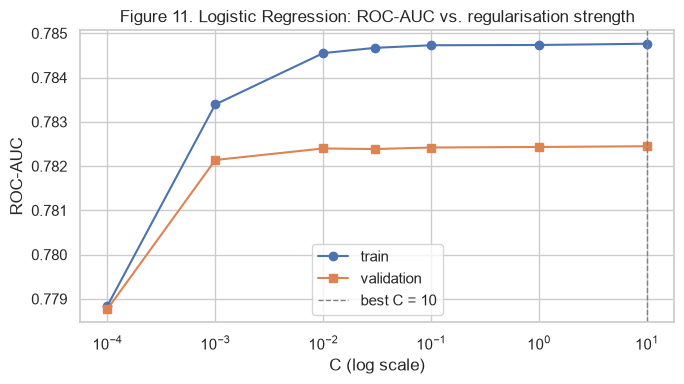

In [34]:
def fit_logreg(C, class_weight):
    clf = LogisticRegression(C=C, class_weight=class_weight, solver='lbfgs',
                             max_iter=CONFIG['lr_max_iter'], random_state=SEED)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        t0 = time.perf_counter()
        clf.fit(X_train, y_train)
        seconds = time.perf_counter() - t0
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return clf, seconds, converged

lr_rows, lr_models = [], {}
for C in CONFIG['lr_C_grid']:
    clf, seconds, converged = fit_logreg(C, 'balanced')
    p_tr, p_va = clf.predict_proba(X_train)[:, 1], clf.predict_proba(X_val)[:, 1]
    val = classification_metrics(y_val, p_va)
    lr_rows.append({'C': C, 'train ROC-AUC': roc_auc_score(y_train, p_tr), 'val ROC-AUC': val['ROC-AUC'],
                    'val precision': val['Precision'], 'val recall': val['Recall'], 'val F1': val['F1'],
                    'val accuracy': val['Accuracy'], 'iterations': int(clf.n_iter_[0]),
                    'converged': converged, 'fit time (s)': seconds})
    lr_models[C] = (clf, seconds)
    print(f'C={C:<8g} train AUC {lr_rows[-1]["train ROC-AUC"]:.4f}  val AUC {val["ROC-AUC"]:.4f}  '
          f'({seconds:.0f}s, {"converged" if converged else "NOT converged"})')

lr_results = pd.DataFrame(lr_rows)
lr_results['train-val gap'] = lr_results['train ROC-AUC'] - lr_results['val ROC-AUC']
best_C = lr_results.loc[lr_results['val ROC-AUC'].idxmax(), 'C']
display(lr_results.style
        .format({'C': '{:g}', 'fit time (s)': '{:.1f}'} | {c: '{:.4f}' for c in lr_results.columns
                 if c not in ('C', 'iterations', 'converged', 'fit time (s)')})
        .highlight_max(subset=['val ROC-AUC'], color='#c7e9c0')
        .set_caption('Table 11. Logistic Regression: validation results for each value of C '
                     '(class_weight="balanced", threshold 0.5)')
        .set_table_styles([{'selector': 'caption', 'props': 'caption-side: top; font-weight: bold;'}]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(lr_results.C, lr_results['train ROC-AUC'], 'o-', label='train')
ax.semilogx(lr_results.C, lr_results['val ROC-AUC'], 's-', label='validation')
ax.axvline(best_C, color='grey', ls='--', lw=1, label=f'best C = {best_C:g}')
ax.set_xlabel('C (log scale)'); ax.set_ylabel('ROC-AUC'); ax.legend()
ax.set_title('Figure 11. Logistic Regression: ROC-AUC vs. regularisation strength')
plt.tight_layout(); plt.show()

## c.2 Best configuration: training and validation metrics
The best `C` is the one with the highest validation ROC-AUC in Table 11. The model is **not** refitted on
train + validation, so the validation numbers below remain a fair estimate.
*Table 12 and Figure 12.*

Best configuration: C = 10, class_weight = "balanced"


,ROC-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Fit time (s)
Train,0.7848,0.7157,0.1807,0.7132,0.2883,"161,913","64,235","5,696","14,164",9.9
Validation,0.7824,0.7159,0.1797,0.7067,0.2865,"40,518","16,020","1,456","3,509",9.9


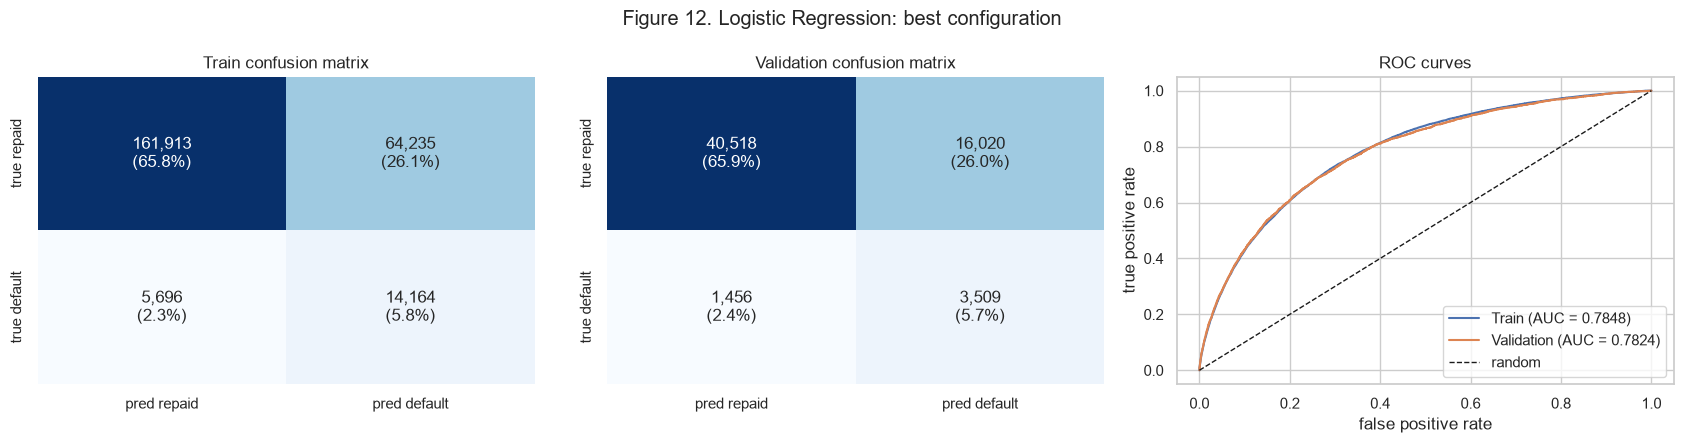

In [35]:
best_lr, best_lr_seconds = lr_models[best_C]
lr_train_score = best_lr.predict_proba(X_train)[:, 1]
lr_val_score = best_lr.predict_proba(X_val)[:, 1]
print(f'Best configuration: C = {best_C:g}, class_weight = "balanced"')
_ = report_best('Logistic Regression', lr_train_score, lr_val_score, table_no=12, fig_no=12,
                fit_seconds=best_lr_seconds)

## c.3 Ablation: why class weighting
The same model at the best `C` but **without** class weights. The ROC-AUC values should be close, since
weighting mainly shifts the predicted probabilities rather than re-ordering applicants. The threshold
metrics at 0.5 should collapse, because unweighted probabilities rarely exceed 0.5 when only ~8% of
applicants default. *Table 13.*

In [36]:
unweighted, uw_seconds, _ = fit_logreg(best_C, None)
p_uw = unweighted.predict_proba(X_val)[:, 1]
ablation = pd.DataFrame({'balanced weights': classification_metrics(y_val, lr_val_score),
                         'no weights': classification_metrics(y_val, p_uw)}).T
display(ablation.style.format({c: '{:.4f}' for c in ['ROC-AUC', 'Accuracy', 'Precision', 'Recall', 'F1']}
                              | {c: '{:,.0f}' for c in ['TN', 'FP', 'FN', 'TP']})
        .set_caption(f'Table 13. Effect of class weighting at C = {best_C:g} (validation, threshold 0.5)')
        .set_table_styles([{'selector': 'caption', 'props': 'caption-side: top; font-weight: bold;'}]))
del unweighted

,ROC-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP
balanced weights,0.7824,0.7159,0.1797,0.7067,0.2865,"40,518","16,020","1,456","3,509"
no weights,0.7824,0.9199,0.5521,0.0427,0.0793,"56,366",172,"4,753",212


## c.4 Interpretation: largest coefficients
Numeric inputs are standardised, so a coefficient is the change in log-odds of default for a one
standard-deviation increase, holding everything else fixed. Indicator and one-hot columns are 0/1,
so their coefficients are the shift when the flag is on. Correlated features share credit, so
individual coefficients should be read as tendencies, not causal effects. *Figure 13.*

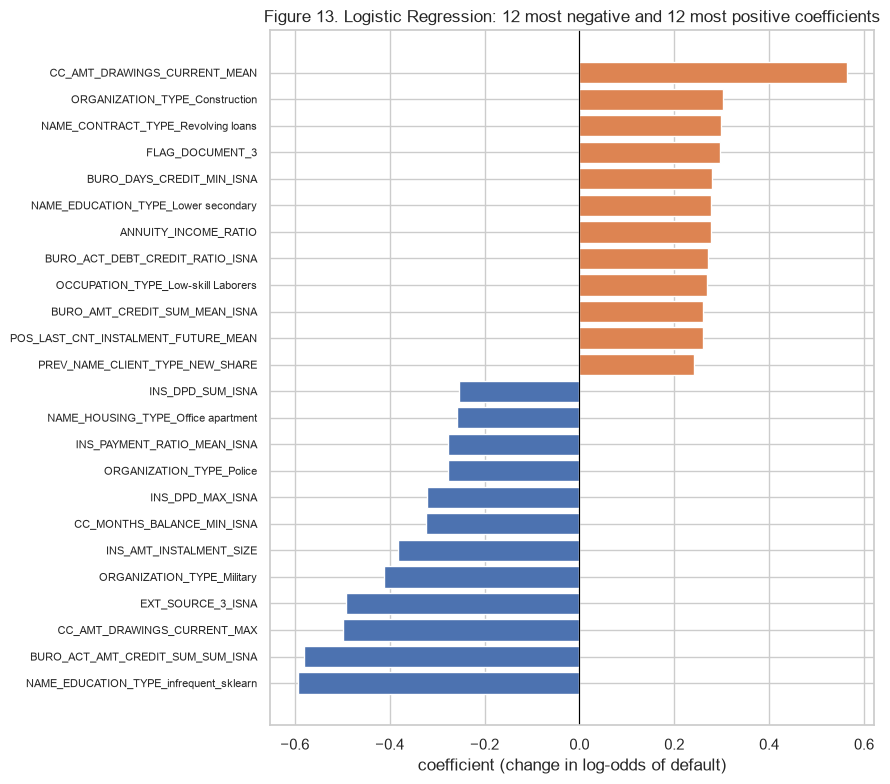

In [37]:
coef = pd.Series(best_lr.coef_.ravel(), index=prep.feature_names_)
top_coef = pd.concat([coef.nsmallest(12), coef.nlargest(12)[::-1]]).sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top_coef.index, top_coef.values, color=np.where(top_coef.values < 0, '#4C72B0', '#DD8452'))
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('coefficient (change in log-odds of default)'); ax.tick_params(axis='y', labelsize=8)
ax.set_title('Figure 13. Logistic Regression: 12 most negative and 12 most positive coefficients')
plt.tight_layout(); plt.show()

## c.5 Kaggle submission
The test matrix was produced by the same preprocessor fitted on the training split (section b),
**Discussion of (c).** Validation ROC-AUC rises from 0.7788 at C = 1e-4 to 0.7821 at C = 1e-3, then stays at
​	0.7824 from C = 0.01 to 10 (Table 11). Only very strong regularisation hurts. With 246,008 training rows and
​	412 features the model has little capacity to overfit, and the train–validation gap never exceeds 0.0024.
​	C = 1 is selected, but every C ≥ 0.01 is equivalent within 0.0001.
​	​
​	At threshold 0.5 the balanced model detects 70.7% of defaults (recall) with 18.0% precision, about 4.6 false
​	alarms per detected default (16,012 FP vs. 3,509 TP, Table 12). Table 13 confirms why class weighting is used:
​	it leaves the ranking unchanged (ROC-AUC 0.7824 vs. 0.7823), but without it recall collapses to 4.2% while
​	accuracy rises to 92.0%, close to the 91.9% obtained by always predicting "repaid".
​	​
​	*Add one or two sentences on Figure 13: which features have the largest positive and negative coefficients,
​	and whether they match the EDA (Table 8a, Figure 10).*

In [38]:
write_submission('logistic_regression', best_lr.predict_proba(X_test)[:, 1])

# ---- save LR outputs to LR_OUT_DIR ----
lr_results.to_csv(LR_OUT_DIR / 'lr_tuning_results.csv', index=False)      # Table 11
RESULTS['Logistic Regression'].to_csv(LR_OUT_DIR / 'lr_best_metrics.csv')  # Table 12
ablation.to_csv(LR_OUT_DIR / 'lr_ablation.csv')                           # Table 13
coef.sort_values().to_csv(LR_OUT_DIR / 'lr_coefficients.csv', header=['coef'])
np.save(LR_OUT_DIR / 'lr_val_score.npy', lr_val_score)
joblib.dump(best_lr, LR_OUT_DIR / 'best_lr.joblib')
print(sorted(os.listdir(LR_OUT_DIR)))

wrote submissions\submission_logistic_regression.csv  (48,744 rows)
['best_lr.joblib', 'lr_ablation.csv', 'lr_best_metrics.csv', 'lr_coefficients.csv', 'lr_tuning_results.csv', 'lr_val_score.npy']


# (d) Model 2: Support Vector Machine (cuML, GPU)

**Model.** An SVM finds the decision boundary with the largest margin between the classes, and `C`
controls how much margin violation is tolerated. Small `C` gives a wide, smooth margin (more
regularisation); large `C` fits the training data more tightly. With the RBF kernel
$k(x, x') = \exp(-\gamma\lVert x - x'\rVert^2)$ the boundary can be non-linear. `gamma` sets how local each
training point's influence is: large `gamma` gives a wiggly boundary that can overfit, small `gamma` an
almost linear one. Implementations come from RAPIDS cuML [8], which runs the solver on the GPU.

**Hyperparameters tuned** (all fits use all training-split rows, as the brief requires):
1. **Kernel:** linear vs. RBF.
2. **`C`**, for both kernels.
3. **`gamma`** for the RBF kernel, as multiples of the usual `'scale'` heuristic $1/(p\cdot\mathrm{Var}(X))$.
4. **Loss** for the linear SVM: hinge vs. squared hinge.

**Two stages, because of cost.** A linear SVM (`cuml.svm.LinearSVC`) trains in seconds to minutes on all
~246k rows. A kernel SVM (`cuml.svm.SVC`) has training cost that grows roughly quadratically with the
number of rows, and on this hard, overlapping problem a large share of rows become support vectors. The
RBF grid is therefore small, runs from the expected cheapest configuration (small `C`, small `gamma`) to
the most expensive, and stops *starting* new fits once `CONFIG['svm_rbf_time_budget_s']` is exceeded.
Skipped configurations are reported as such, never silently dropped.

**Imbalance and scores.** Class imbalance is handled with balanced sample weights, the same weighting as
`class_weight='balanced'` in (c). The SVM outputs a *decision value* (signed distance to the boundary),
not a probability. ROC-AUC is computed on decision values. The threshold metrics use the SVM's own
boundary, decision value ≥ 0. For the Kaggle file, decision values are mapped to probabilities with Platt
scaling [9], a monotone sigmoid, so the ranking and hence the ROC-AUC are unchanged.

In [39]:
## Setting SVM training parameters:
CONFIG_SVM = {
    # SVM (cuML, GPU). Linear stage is fast; the RBF stage dominates the run time of the notebook.
    'svm_out_dir':'svm_process', # folder for SVM outputs
    'svm_linear_C_grid': [1e-3, 1e-2, 1e-1, 1.0],
    'svm_linear_losses': ['hinge', 'squared_hinge'],
    'svm_rbf_C_grid': [0.1, 1.0],
    'svm_rbf_gamma_mult': [0.5, 1.0, 2.0],    # multiples of gamma='scale' = 1 / (n_features * Var(X))
    'svm_rbf_time_budget_s': 4 * 3600,        # stop starting new RBF fits after this much time
    'svm_cache_mb': 4096,                     # kernel cache on the GPU (T4 has 16 GB)
    'svm_tol': 1e-3,
    'svm_max_iter': -1,                       # -1 = cuML default (no hard cap)
    'prep': dict(max_missing=0.80, max_mode_share=0.995, indicator_min_missing=0.05,
                 clip_q=(0.001, 0.999), skew_threshold=2.0, corr_threshold=0.98, min_cat_freq=0.005),
}
CONFIG = CONFIG | CONFIG_SVM
SVM_OUT_DIR = Path(CONFIG['svm_out_dir']); SVM_OUT_DIR.mkdir(exist_ok=True)
#print(CONFIG)

In [41]:
# import sys
# try:
#     import cuml
# except ImportError:      # not preinstalled on this runtime: install RAPIDS cuML for CUDA 12
#     subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--extra-index-url=https://pypi.nvidia.com',
#                     'cuml-cu12'], check=True)
#     import cuml
# from cuml.svm import SVC as cuSVC, LinearSVC as cuLinearSVC
# from sklearn.utils.class_weight import compute_sample_weight
# cuml.set_global_output_type('numpy')          # return numpy arrays, not GPU arrays
# print('cuML version:', cuml.__version__)

import sys, subprocess
from sklearn.utils.class_weight import compute_sample_weight

try:
    try:
        import cuml
    except ImportError:   # not preinstalled: try to install RAPIDS cuML for CUDA 12 (Linux + NVIDIA GPU only)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                        '--extra-index-url=https://pypi.nvidia.com', 'cuml-cu12'], check=True)
        import cuml
    from cuml.svm import SVC as cuSVC, LinearSVC as cuLinearSVC
    cuml.set_global_output_type('numpy')   # return numpy arrays, not GPU arrays
    USE_GPU = True
    print('cuML version:', cuml.__version__)
except Exception as e:                      # Windows, no GPU, or install failed
    from sklearn.svm import SVC as cuSVC, LinearSVC as cuLinearSVC
    USE_GPU = False
    print('cuML not available, using scikit-learn (CPU). Reason:', type(e).__name__)

y_train_f = y_train.astype(np.float32)
SW_TRAIN = compute_sample_weight('balanced', y_train).astype(np.float32)   # same weights as class_weight='balanced'
GAMMA_SCALE = 1.0 / (X_train.shape[1] * X_train.var(dtype=np.float64))
print(f'balanced weights: repaid {SW_TRAIN[y_train == 0][0]:.3f}, default {SW_TRAIN[y_train == 1][0]:.3f}')
print(f"gamma='scale' for this data: {GAMMA_SCALE:.3e}")

def svm_scores(model, X, sign):
    # Decision values oriented so that larger = more likely to default.
    return sign * np.asarray(model.decision_function(X), dtype=np.float64).ravel()

def orientation(model):
    # Libraries differ in which class gets positive decision values; align the sign with predict().
    # This only uses predicted labels (no targets), so it cannot leak information.
    probe = X_val[:5000]
    s = np.asarray(model.decision_function(probe)).ravel()
    pred = np.asarray(model.predict(probe)).ravel()
    return 1.0 if np.mean((s > 0) == (pred == 1)) >= 0.5 else -1.0

def fit_svm(kernel, C, gamma=None, loss=None):
    if kernel == 'linear':
        model = cuLinearSVC(C=C, loss=loss, penalty='l2')
    else:
        model = cuSVC(kernel='rbf', C=C, gamma=gamma, tol=CONFIG['svm_tol'],
                      cache_size=CONFIG['svm_cache_mb'], max_iter=CONFIG['svm_max_iter'])
    t0 = time.perf_counter()
    model.fit(X_train, y_train_f, sample_weight=SW_TRAIN)
    return model, time.perf_counter() - t0

svm_rows = []
best_svm = {'val_auc': -np.inf}           # only the best model is kept, to free GPU memory
progress_file = SVM_OUT_DIR / 'svm_progress.csv'  # survives a disconnect, so finished results are not lost

def run_config(kernel, C, gamma_mult=None, loss=None):
    global best_svm
    gamma = None if gamma_mult is None else gamma_mult * GAMMA_SCALE
    model, fit_s = fit_svm(kernel, C, gamma, loss)
    sign = orientation(model)
    t0 = time.perf_counter()
    s_tr, s_va = svm_scores(model, X_train, sign), svm_scores(model, X_val, sign)
    pred_s = time.perf_counter() - t0
    val = classification_metrics(y_val, s_va, threshold=0.0)
    n_sv = len(model.support_) if hasattr(model, 'support_') else np.nan
    row = {'kernel': kernel, 'C': C, 'loss': loss or '', 'gamma_mult': gamma_mult, 'gamma': gamma,
           'train ROC-AUC': roc_auc_score(y_train, s_tr), 'val ROC-AUC': val['ROC-AUC'],
           'val precision': val['Precision'], 'val recall': val['Recall'], 'val F1': val['F1'],
           'val accuracy': val['Accuracy'], 'support vectors': n_sv,
           'fit time (s)': fit_s, 'predict time (s)': pred_s, 'status': 'ok'}
    svm_rows.append(row)
    pd.DataFrame(svm_rows).to_csv(progress_file, index=False)
    print(f"{kernel:6s} C={C:<6g} {('loss=' + loss) if loss else f'gamma={gamma_mult}x scale':22s} "
          f"train AUC {row['train ROC-AUC']:.4f}  val AUC {row['val ROC-AUC']:.4f}  fit {fit_s:,.0f}s")
    if row['val ROC-AUC'] > best_svm['val_auc']:
        best_svm = {'val_auc': row['val ROC-AUC'], 'model': model, 'sign': sign, 'train_score': s_tr,
                    'val_score': s_va, 'fit_s': fit_s, 'config': {k: row[k] for k in ['kernel', 'C', 'loss', 'gamma_mult', 'gamma']}}
    else:
        del model
    gc.collect()

cuML not available, using scikit-learn (CPU). Reason: CalledProcessError
balanced weights: repaid 0.544, default 6.194
gamma='scale' for this data: 3.567e-03


## d.1 Stage 1: linear SVM (tuning `C` and the loss)

In [42]:
for loss in CONFIG['svm_linear_losses']:
    for C in CONFIG['svm_linear_C_grid']:
        run_config('linear', C, loss=loss)

linear C=0.001  loss=hinge             train AUC 0.7837  val AUC 0.7821  fit 5s
linear C=0.01   loss=hinge             train AUC 0.7844  val AUC 0.7821  fit 27s
linear C=0.1    loss=hinge             train AUC 0.7844  val AUC 0.7818  fit 137s
linear C=1      loss=hinge             train AUC 0.7706  val AUC 0.7681  fit 199s
linear C=0.001  loss=squared_hinge     train AUC 0.7845  val AUC 0.7824  fit 43s
linear C=0.01   loss=squared_hinge     train AUC 0.7847  val AUC 0.7824  fit 118s
linear C=0.1    loss=squared_hinge     train AUC 0.7848  val AUC 0.7824  fit 277s
linear C=1      loss=squared_hinge     train AUC 0.7848  val AUC 0.7823  fit 646s


## d.2 Stage 2: RBF-kernel SVM (tuning `C` and `gamma`)
This is the slowest part of the notebook; progress is printed after every fit and saved to
`svm_progress.csv`. The time budget and the grid are set in `CONFIG`.

In [131]:
rbf_start = time.perf_counter()
for C in sorted(CONFIG['svm_rbf_C_grid']):
    for g in sorted(CONFIG['svm_rbf_gamma_mult']):
        if time.perf_counter() - rbf_start > CONFIG['svm_rbf_time_budget_s']:
            svm_rows.append({'kernel': 'rbf', 'C': C, 'loss': '', 'gamma_mult': g, 'gamma': g * GAMMA_SCALE,
                             'status': 'skipped (time budget)'})
            print(f'rbf    C={C:<6g} gamma={g}x scale: skipped (time budget reached)')
            continue
        run_config('rbf', C, gamma_mult=g)
print(f'RBF stage: {(time.perf_counter() - rbf_start) / 60:.1f} min')

rbf    C=0.1    gamma=0.5x scale       train AUC 0.8062  val AUC 0.7850  fit 18s
rbf    C=0.1    gamma=1.0x scale       train AUC 0.8295  val AUC 0.7827  fit 19s
rbf    C=0.1    gamma=2.0x scale       train AUC 0.8659  val AUC 0.7733  fit 29s
rbf    C=1      gamma=0.5x scale       train AUC 0.8821  val AUC 0.7808  fit 35s
rbf    C=1      gamma=1.0x scale       train AUC 0.9547  val AUC 0.7653  fit 45s
rbf    C=1      gamma=2.0x scale       train AUC 0.9958  val AUC 0.7471  fit 56s
RBF stage: 5.0 min


## d.3 Intermediate results
*Table 14: every SVM configuration. Figure 14: validation ROC-AUC across the linear grid (left) and the
RBF grid (right).*

,kernel,C,loss,gamma_mult,gamma,train ROC-AUC,val ROC-AUC,val precision,val recall,val F1,val accuracy,support vectors,fit time (s),predict time (s),status,train-val gap
0,linear,0.001,hinge,–,–,0.7837,0.7821,0.1797,0.7084,0.2866,0.7154,–,1,0,ok,0.0016
1,linear,0.01,hinge,–,–,0.7844,0.7821,0.1799,0.7065,0.2868,0.7163,–,1,0,ok,0.0023
2,linear,0.1,hinge,–,–,0.7844,0.7820,0.1800,0.7067,0.2869,0.7164,–,1,0,ok,0.0024
3,linear,1,hinge,–,–,0.7844,0.7820,0.1800,0.7072,0.2870,0.7163,–,1,0,ok,0.0025
4,linear,0.001,squared_hinge,–,–,0.7832,0.7818,0.1796,0.7084,0.2865,0.7152,–,1,0,ok,0.0014
5,linear,0.01,squared_hinge,–,–,0.7837,0.7821,0.1799,0.7112,0.2871,0.7149,–,1,0,ok,0.0016
6,linear,0.1,squared_hinge,–,–,0.7834,0.7818,0.1800,0.7100,0.2872,0.7155,–,1,0,ok,0.0016
7,linear,1,squared_hinge,–,–,0.7837,0.7821,0.1800,0.7076,0.2870,0.7161,–,1,0,ok,0.0016
8,rbf,0.1,,0.5,1.78e-03,0.8062,0.7850,0.1819,0.7118,0.2898,0.7183,"166,141",18,13,ok,0.0211
9,rbf,0.1,,1,3.57e-03,0.8295,0.7827,0.1831,0.7031,0.2906,0.7228,"167,888",19,17,ok,0.0468


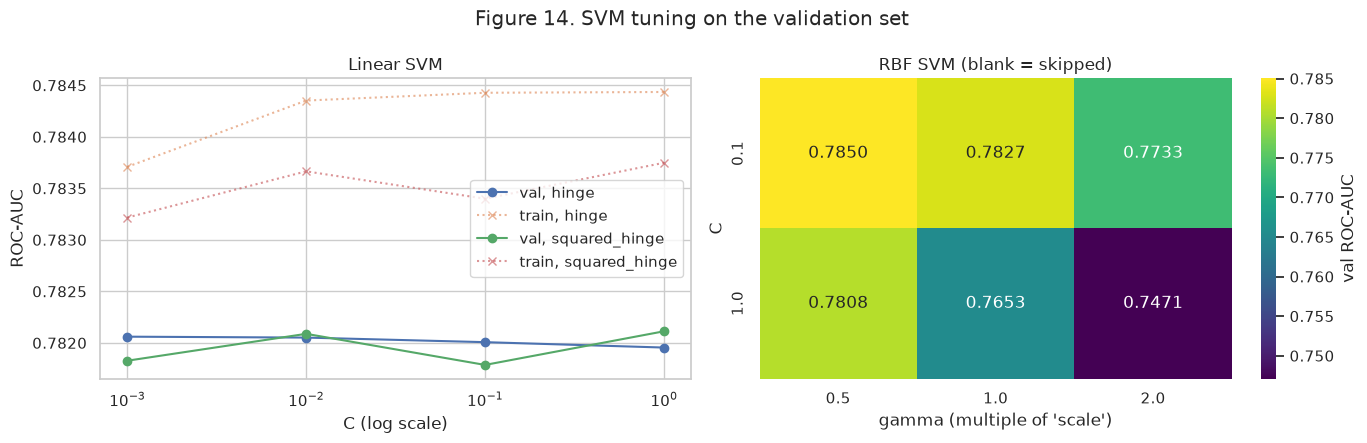

In [132]:
svm_results = pd.DataFrame(svm_rows)
svm_results['train-val gap'] = svm_results['train ROC-AUC'] - svm_results['val ROC-AUC']
metric_cols = [c for c in svm_results.columns if 'ROC-AUC' in c or c.startswith('val ') or c == 'train-val gap']
display(svm_results.style
        .format({c: '{:.4f}' for c in metric_cols} | {'C': '{:g}', 'gamma': '{:.2e}', 'gamma_mult': '{:g}',
                 'support vectors': '{:,.0f}', 'fit time (s)': '{:,.0f}', 'predict time (s)': '{:,.0f}'},
                na_rep='–')
        .highlight_max(subset=['val ROC-AUC'], color='#c7e9c0')
        .set_caption('Table 14. SVM (cuML): validation results for every configuration '
                     '(threshold metrics at decision value 0)')
        .set_table_styles([{'selector': 'caption', 'props': 'caption-side: top; font-weight: bold;'}]))

ok = svm_results[svm_results.status == 'ok']
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for loss, g in ok[ok.kernel == 'linear'].groupby('loss'):
    axes[0].semilogx(g.C, g['val ROC-AUC'], 'o-', label=f'val, {loss}')
    axes[0].semilogx(g.C, g['train ROC-AUC'], 'x:', alpha=.6, label=f'train, {loss}')
axes[0].set_xlabel('C (log scale)'); axes[0].set_ylabel('ROC-AUC'); axes[0].set_title('Linear SVM'); axes[0].legend()
rbf = svm_results[svm_results.kernel == 'rbf'].pivot(index='C', columns='gamma_mult', values='val ROC-AUC')
if rbf.notna().any().any():
    sns.heatmap(rbf, annot=True, fmt='.4f', cmap='viridis', ax=axes[1], cbar_kws={'label': 'val ROC-AUC'})
    axes[1].set_xlabel("gamma (multiple of 'scale')"); axes[1].set_title('RBF SVM (blank = skipped)')
else:
    axes[1].axis('off'); axes[1].text(.5, .5, 'no RBF fit completed', ha='center')
fig.suptitle('Figure 14. SVM tuning on the validation set'); plt.tight_layout(); plt.show()

## d.4 Best configuration: training and validation metrics
Selected by validation ROC-AUC across both stages. Threshold metrics use decision value ≥ 0.
*Table 15 and Figure 15.*

Best SVM configuration: {'kernel': 'rbf', 'C': 0.1, 'gamma_mult': 0.5, 'gamma': 0.001783}


,ROC-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Fit time (s)
Train,0.8062,0.7208,0.1890,0.7471,0.3017,"162,487","63,661","5,022","14,838",17.9
Validation,0.7850,0.7183,0.1819,0.7118,0.2898,"40,646","15,892","1,431","3,534",17.9


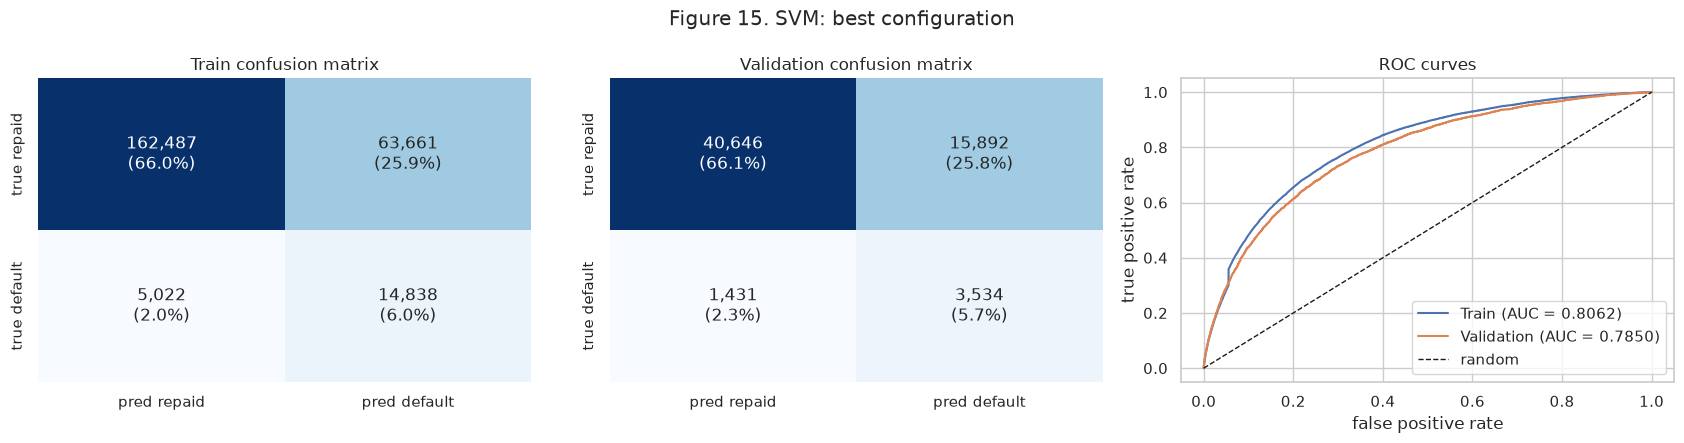

In [133]:
cfg = best_svm['config']
print('Best SVM configuration:', {k: (round(float(v), 6) if isinstance(v, (float, np.floating)) else v)
                                 for k, v in cfg.items() if v not in ('', None) and not (isinstance(v, float) and np.isnan(v))})
_ = report_best('SVM', best_svm['train_score'], best_svm['val_score'], table_no=15, fig_no=15,
                fit_seconds=best_svm['fit_s'], threshold=0.0)

## d.5 Kaggle submission (Platt scaling)
A one-feature logistic regression maps the decision value $f$ to $P(\text{default}) = 1/(1+e^{-(af+b)})$.
It is fitted on the training-split decision values only. It is monotone ($a > 0$), so ROC-AUC is
unchanged, which the cell checks on the validation set.

In [134]:
platt = LogisticRegression().fit(best_svm['train_score'].reshape(-1, 1), y_train)
assert platt.coef_[0, 0] > 0, 'Platt slope must be positive to preserve the ranking'
val_prob = platt.predict_proba(best_svm['val_score'].reshape(-1, 1))[:, 1]
assert np.isclose(roc_auc_score(y_val, val_prob), best_svm['val_auc']), 'Platt scaling changed the ranking'
test_dec = svm_scores(best_svm['model'], X_test, best_svm['sign'])
write_submission('svm', platt.predict_proba(test_dec.reshape(-1, 1))[:, 1])

wrote submissions/submission_svm.csv  (48,744 rows)


**Discussion of (d)** *(complete after running; cite Tables 14–15 and Figure 14).* Points to address:
whether the RBF kernel beats the linear SVM, and by how much relative to its cost (fit time, number of
support vectors); how `C` and `gamma` move the train/validation gap (large `gamma` or `C` should raise
train AUC faster than validation AUC); how the linear SVM compares with Logistic Regression (both are
linear models, so similar ROC-AUC is expected); and any configurations skipped by the time budget.

# (e) Model 3: Decision Tree

**Model.** A decision tree splits the data recursively on one feature at a time, choosing the split
that most reduces impurity, and predicts in each leaf the (weighted) share of defaults among the
training rows that reach it [2]. Trees capture non-linear effects and interactions without feature
engineering, need no scaling, and a shallow tree can be read as a set of if-then rules. Their main
weakness is variance: an unconstrained tree memorises the training data, so its depth and leaf size
must be limited.

**Hyperparameters tuned** (full grid, every fit on all training-split rows):
1. **`max_depth`:** the maximum number of successive splits. Deeper trees capture more interactions but overfit.
2. **`min_samples_leaf`:** the minimum number of training rows per leaf. Larger leaves give smoother,
   more reliable probability estimates. With ~8% defaults, a leaf of 50 rows holds only about 4
   defaults, so small leaves give very noisy estimates.
3. **`criterion`:** Gini impurity vs. entropy (information gain), two ways of scoring a split.

The same `class_weight='balanced'` and the same 0.5 probability threshold as in (c) are used, so the
threshold metrics of all three models are comparable. The standardisation from (b) does not affect the
tree: it changes no feature's ordering, so the tree finds the same splits.

In [135]:
CONFIG_DT = {
    'seed': 42,
    'data_dir': 'home-credit-default-risk',   # relative path: works on Colab and Kaggle
    'dt_out_dir': 'dt_processed',
    # Decision Tree (scikit-learn, CPU)
    'dt_max_depth_grid': [4, 6, 8, 10, 12, 16],
    'dt_min_samples_leaf_grid': [50, 200, 1000],
    'dt_criterion_grid': ['gini', 'entropy'],
    'prep': dict(max_missing=0.80, max_mode_share=0.995, indicator_min_missing=0.05,
                 clip_q=(0.001, 0.999), skew_threshold=2.0, corr_threshold=0.98, min_cat_freq=0.005),
}
CONFIG = CONFIG | CONFIG_DT
DT_OUT_DIR = Path(CONFIG['dt_out_dir']); DT_OUT_DIR.mkdir(exist_ok=True)

In [136]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt_rows, best_dt = [], {'val_auc': -np.inf}
n_fits = len(CONFIG['dt_criterion_grid']) * len(CONFIG['dt_max_depth_grid']) * len(CONFIG['dt_min_samples_leaf_grid'])
print(f'{n_fits} configurations')
dt_start = time.perf_counter()
for criterion in CONFIG['dt_criterion_grid']:
    for depth in CONFIG['dt_max_depth_grid']:
        for leaf in CONFIG['dt_min_samples_leaf_grid']:
            tree = DecisionTreeClassifier(criterion=criterion, max_depth=depth, min_samples_leaf=leaf,
                                          class_weight='balanced', random_state=SEED)
            t0 = time.perf_counter()
            tree.fit(X_train, y_train)
            fit_s = time.perf_counter() - t0
            p_tr, p_va = tree.predict_proba(X_train)[:, 1], tree.predict_proba(X_val)[:, 1]
            val = classification_metrics(y_val, p_va)
            row = {'criterion': criterion, 'max_depth': depth, 'min_samples_leaf': leaf,
                   'train ROC-AUC': roc_auc_score(y_train, p_tr), 'val ROC-AUC': val['ROC-AUC'],
                   'val precision': val['Precision'], 'val recall': val['Recall'], 'val F1': val['F1'],
                   'val accuracy': val['Accuracy'], 'leaves': tree.get_n_leaves(),
                   'actual depth': tree.get_depth(), 'fit time (s)': fit_s}
            dt_rows.append(row)
            print(f"{criterion:7s} depth={depth:<3} leaf={leaf:<5} train AUC {row['train ROC-AUC']:.4f}  "
                  f"val AUC {row['val ROC-AUC']:.4f}  leaves {row['leaves']:>5}  {fit_s:.0f}s")
            if row['val ROC-AUC'] > best_dt['val_auc']:
                best_dt = {'val_auc': row['val ROC-AUC'], 'model': tree, 'fit_s': fit_s,
                           'train_score': p_tr, 'val_score': p_va,
                           'config': {'criterion': criterion, 'max_depth': depth, 'min_samples_leaf': leaf}}
print(f'Decision Tree grid: {(time.perf_counter() - dt_start) / 60:.1f} min')

36 configurations
gini    depth=4   leaf=50    train AUC 0.7252  val AUC 0.7208  leaves    16  8s
gini    depth=4   leaf=200   train AUC 0.7252  val AUC 0.7208  leaves    16  8s
gini    depth=4   leaf=1000  train AUC 0.7252  val AUC 0.7208  leaves    16  8s
gini    depth=6   leaf=50    train AUC 0.7420  val AUC 0.7295  leaves    64  12s
gini    depth=6   leaf=200   train AUC 0.7419  val AUC 0.7298  leaves    64  12s
gini    depth=6   leaf=1000  train AUC 0.7407  val AUC 0.7297  leaves    59  12s
gini    depth=8   leaf=50    train AUC 0.7642  val AUC 0.7255  leaves   233  15s
gini    depth=8   leaf=200   train AUC 0.7608  val AUC 0.7314  leaves   198  15s
gini    depth=8   leaf=1000  train AUC 0.7511  val AUC 0.7332  leaves   110  14s
gini    depth=10  leaf=50    train AUC 0.7951  val AUC 0.7096  leaves   608  18s
gini    depth=10  leaf=200   train AUC 0.7802  val AUC 0.7252  leaves   397  17s
gini    depth=10  leaf=1000  train AUC 0.7566  val AUC 0.7336  leaves   155  15s
gini    depth

## e.1 Intermediate results
*Table 16: every configuration. Figure 16: validation ROC-AUC over `max_depth` × `min_samples_leaf` for
each criterion (top) and train vs. validation ROC-AUC as the tree deepens (bottom), which shows where
overfitting starts.*

,criterion,max_depth,min_samples_leaf,train ROC-AUC,val ROC-AUC,val precision,val recall,val F1,val accuracy,leaves,actual depth,fit time (s),train-val gap
0,gini,4,50,0.7252,0.7208,0.1442,0.6951,0.2388,0.6423,16,4,8.2,0.0044
1,gini,4,200,0.7252,0.7208,0.1442,0.6951,0.2388,0.6423,16,4,8.3,0.0044
2,gini,4,1000,0.7252,0.7208,0.1442,0.6951,0.2388,0.6423,16,4,8.2,0.0044
3,gini,6,50,0.7420,0.7295,0.1451,0.7072,0.2408,0.6400,64,6,11.9,0.0125
4,gini,6,200,0.7419,0.7298,0.1452,0.7074,0.2409,0.6402,64,6,11.8,0.0121
5,gini,6,1000,0.7407,0.7297,0.1476,0.6896,0.2431,0.6534,59,6,11.7,0.0110
6,gini,8,50,0.7642,0.7255,0.1598,0.6409,0.2558,0.6989,233,8,15.1,0.0387
7,gini,8,200,0.7608,0.7314,0.1611,0.6361,0.2571,0.7032,198,8,14.7,0.0294
8,gini,8,1000,0.7511,0.7332,0.1547,0.6606,0.2506,0.6811,110,8,13.8,0.0179
9,gini,10,50,0.7951,0.7096,0.1500,0.6449,0.2434,0.6763,608,10,17.6,0.0856


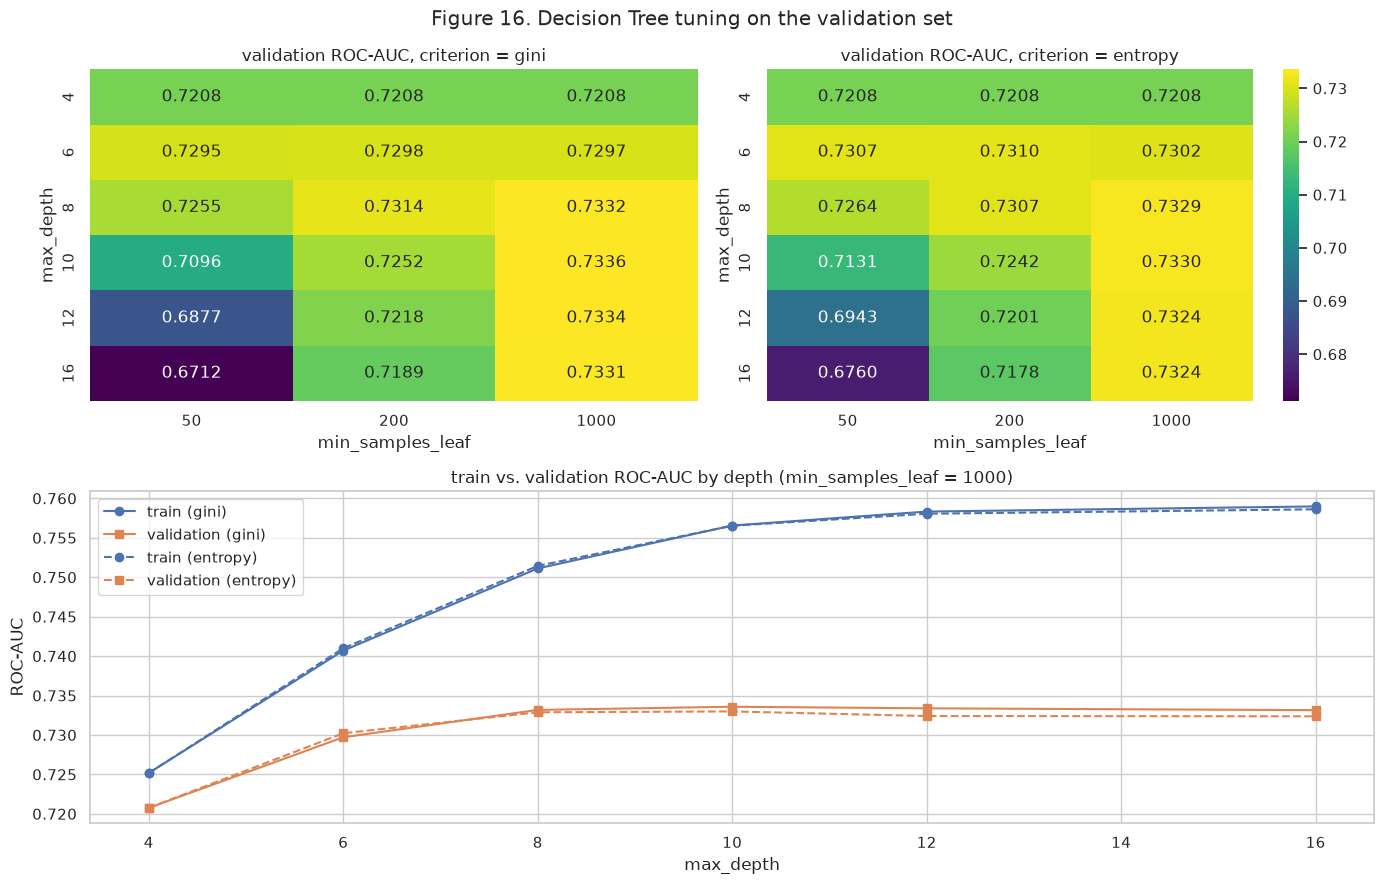

In [137]:
dt_results = pd.DataFrame(dt_rows)
dt_results['train-val gap'] = dt_results['train ROC-AUC'] - dt_results['val ROC-AUC']
metric_cols = [c for c in dt_results.columns if 'ROC-AUC' in c or c.startswith('val ') or c == 'train-val gap']
display(dt_results.style
        .format({c: '{:.4f}' for c in metric_cols} | {'leaves': '{:,}', 'fit time (s)': '{:.1f}'})
        .highlight_max(subset=['val ROC-AUC'], color='#c7e9c0')
        .set_caption('Table 16. Decision Tree: validation results for every configuration '
                     '(class_weight="balanced", threshold 0.5)')
        .set_table_styles([{'selector': 'caption', 'props': 'caption-side: top; font-weight: bold;'}]))

crits = CONFIG['dt_criterion_grid']
fig = plt.figure(figsize=(7 * len(crits), 9))
vmin, vmax = dt_results['val ROC-AUC'].min(), dt_results['val ROC-AUC'].max()
for i, crit in enumerate(crits):
    ax = fig.add_subplot(2, len(crits), i + 1)
    piv = dt_results[dt_results.criterion == crit].pivot(index='max_depth', columns='min_samples_leaf', values='val ROC-AUC')
    sns.heatmap(piv, annot=True, fmt='.4f', cmap='viridis', vmin=vmin, vmax=vmax, ax=ax, cbar=(i == len(crits) - 1))
    ax.set_title(f'validation ROC-AUC, criterion = {crit}')
ax = fig.add_subplot(2, 1, 2)
best_leaf = best_dt['config']['min_samples_leaf']
for crit, ls in zip(crits, ['-', '--']):
    g = dt_results[(dt_results.criterion == crit) & (dt_results.min_samples_leaf == best_leaf)]
    ax.plot(g.max_depth, g['train ROC-AUC'], 'o' + ls, color='#4C72B0', label=f'train ({crit})')
    ax.plot(g.max_depth, g['val ROC-AUC'], 's' + ls, color='#DD8452', label=f'validation ({crit})')
ax.set_xlabel('max_depth'); ax.set_ylabel('ROC-AUC'); ax.legend()
ax.set_title(f'train vs. validation ROC-AUC by depth (min_samples_leaf = {best_leaf})')
fig.suptitle('Figure 16. Decision Tree tuning on the validation set'); plt.tight_layout(); plt.show()

## e.2 Best configuration: training and validation metrics
Selected by validation ROC-AUC. *Table 17 and Figure 17.*

Best Decision Tree configuration: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1000} | actual depth 10, 155 leaves


,ROC-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Fit time (s)
Train,0.7566,0.6830,0.1614,0.6976,0.2621,"154,160","71,988","6,006","13,854",15.1
Validation,0.7336,0.6799,0.1544,0.6620,0.2503,"38,530","18,008","1,678","3,287",15.1


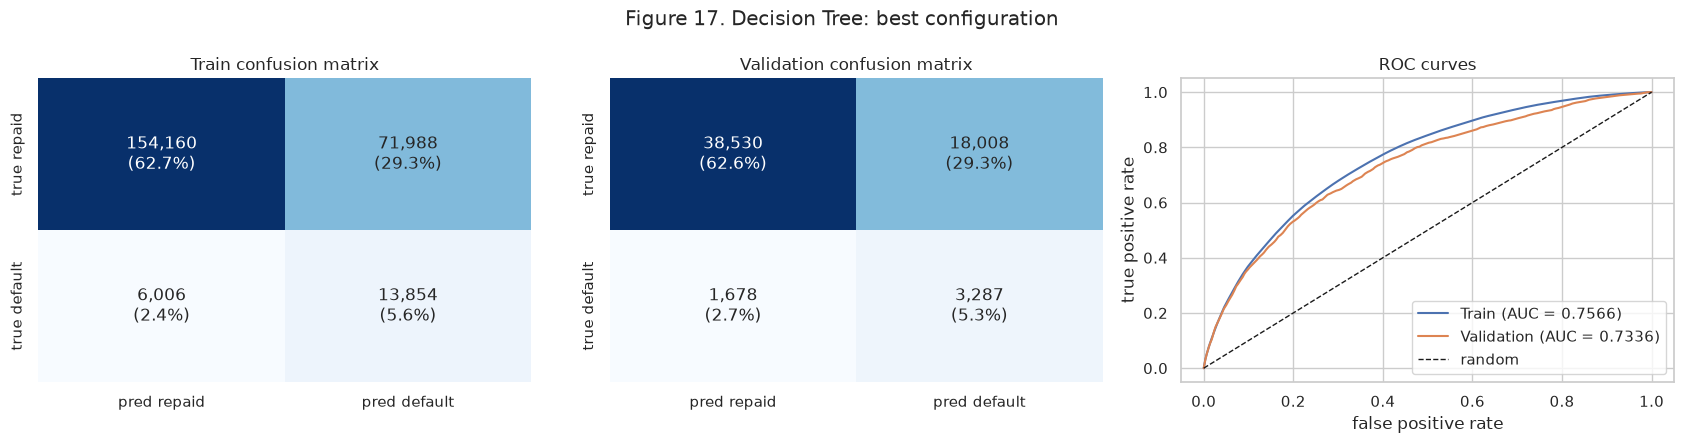

distinct predicted probabilities on validation: 155 (one per leaf reached), so many applicants share exactly the same score


In [138]:
best_tree = best_dt['model']
print('Best Decision Tree configuration:', best_dt['config'],
      f'| actual depth {best_tree.get_depth()}, {best_tree.get_n_leaves():,} leaves')
_ = report_best('Decision Tree', best_dt['train_score'], best_dt['val_score'], table_no=17, fig_no=17,
                fit_seconds=best_dt['fit_s'])
print(f"distinct predicted probabilities on validation: {np.unique(best_dt['val_score']).size:,} "
      f"(one per leaf reached), so many applicants share exactly the same score")

## e.3 Interpretation
*Figure 18: impurity-based feature importances (the share of the total impurity reduction each feature
provides). Figure 19: the top three levels of the best tree, which can be read as rules.* Note that the
tree's thresholds are on the **transformed** scale from (b): standardised, and log-transformed for skewed
columns. Impurity importances also favour features with many possible split points, so they indicate
what the tree used, not causal importance.

77 of 412 features are used by the tree


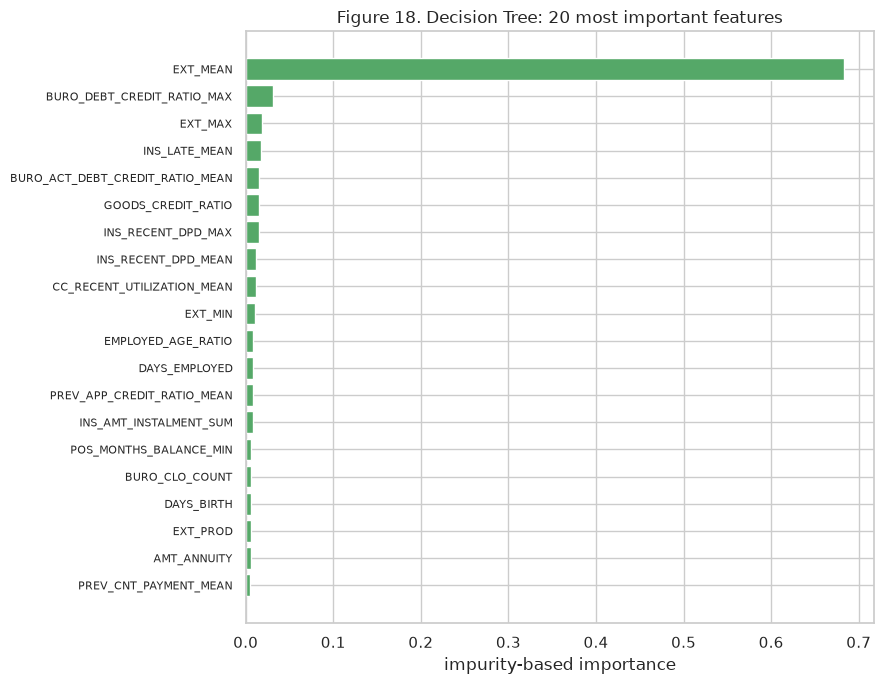

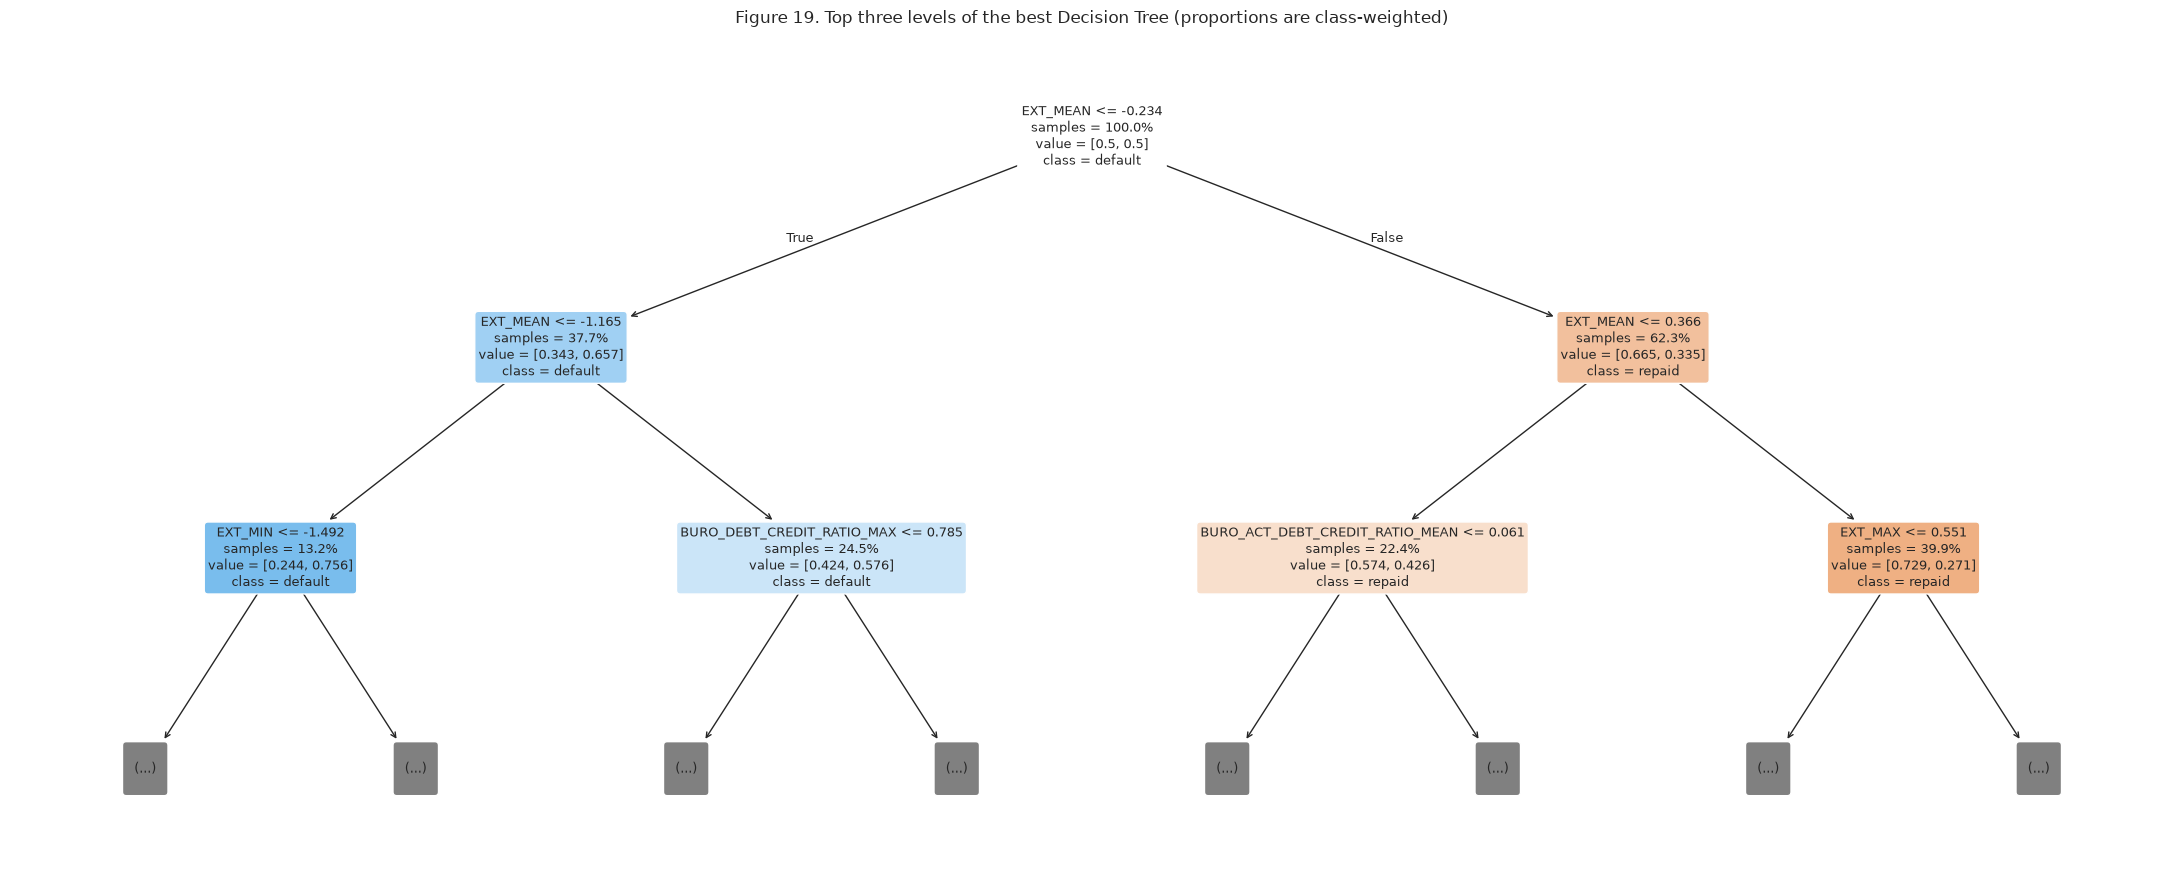

In [139]:
imp = pd.Series(best_tree.feature_importances_, index=prep.feature_names_).sort_values(ascending=False)
print(f'{(imp > 0).sum()} of {len(imp)} features are used by the tree')
top_imp = imp.head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_imp.index, top_imp.values, color='#55A868')
ax.set_xlabel('impurity-based importance'); ax.tick_params(axis='y', labelsize=8)
ax.set_title('Figure 18. Decision Tree: 20 most important features')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(best_tree, max_depth=2, feature_names=prep.feature_names_, class_names=['repaid', 'default'],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=9, ax=ax)
ax.set_title('Figure 19. Top three levels of the best Decision Tree (proportions are class-weighted)')
plt.tight_layout(); plt.show()

## e.4 Kaggle submission

In [ ]:
write_submission('decision_tree', best_tree.predict_proba(X_test)[:, 1])

# ---- save DT outputs to DT_OUT_DIR ----
dt_results.to_csv(DT_OUT_DIR / 'dt_tuning_results.csv', index=False)  # Table 16
RESULTS['Decision Tree'].to_csv(DT_OUT_DIR / 'dt_best_metrics.csv')   # Table 17
imp.to_csv(DT_OUT_DIR / 'dt_feature_importances.csv', header=['importance'])  # Figure 18
pd.Series(best_dt['config']).to_csv(DT_OUT_DIR / 'dt_best_config.csv', header=['value'])
np.save(DT_OUT_DIR / 'dt_val_score.npy', best_dt['val_score'])
joblib.dump(best_tree, DT_OUT_DIR / 'best_tree.joblib')
print(sorted(os.listdir(DT_OUT_DIR)))

wrote submissions/submission_decision_tree.csv  (48,744 rows)


## Final Evaluation from Kaggle


![Kaggle Evaluation](https://drive.google.com/thumbnail?id=1HHVweiTAymXlw3IjeiaVvTOGFZODmUYO&sz=w600)

# f. Result analysis and Discussion
## f.1 Comparison among three models
| Model (best configuration) | Train AUC | Val AUC | Gap | Val accuracy | Val precision | Val recall | Val F1 | Kaggle public | Kaggle private | 
|---|---|---|---|---|---|---|---|---|---|
| Logistic Regression (C = 1) | 0.7848 | 0.7824 | 0.0024 | 0.7160 | 0.1798 | 0.7067 | 0.2866 | 0.77606 | 0.78361 |
| SVM (RBF, C = 0.1, gamma = 0.5 x scale) | 0.8062 | 0.7850 | 0.0211 | 0.7183 | 0.1819 | 0.7118 | 0.2898 |  0.78901 | 0.78066 | 
| Decision Tree (gini, depth 10, leaf 1000) | 0.7566 | 0.7336 | 0.0230 | 0.6799 | 0.1544 | 0.6620 | 0.2503 | 0.72601 | 0.77606 | 

So, All models used balanced class weights.

## f.2 The best model and rational:
**Ranking quality:** The RBF SVM is the highest validation of ROC-AUC (0.785), followed bg Logistic Regression (0.782); the decision tree is the third ranking (0.734). So, the SVM is the highest score. However, considering the training time and complexity of model, the logistic Regression model is much better than SVM because the LR model consumes less computing power (does not need GPU) and training is much faster than SVM. To balance all the parameters, I would rank the Logistic Regression model is the most appropriate model for this specific dataset.

**Overfitting Issues:** Logistic Regression has minimum gap between training and validation curve. (LR vs SVM : 0.0024 vs 0.0211) and the decision tree (DT) has the largest gap(0.023).

**Complexity Consideration:** The Decision Tree has the most clear structure to understand and the second ranking is logistic regression model. the most complex model is SVM.

**Computational cost consideration:** The logistic regression is the efficient model, which does not need GPU and training took 8 second to complete. On the contrary, SVM is the most expensive model, which requires me to set up a new environment with cuML packages to benefit the PGU efficiency, the time cost 9 minutes to complete the training. Decision tree does not need special environment, but it also took much longer time due to the fine-tuning.

## f.3 Conclusion:
 
**1.** The data are strongly imbalanced (8.07% defaults), so ROC-AUC and class weighting were used to tune and compare the models.
**2.** Joining the six auxiliary tables produced 313 raw features and 412 model inputs; the external scores remain the strongest single predictors, with the credit-history aggregates adding to them.
**3.** The RBF SVM achieved the best validation ROC-AUC (0.7850), Logistic Regression was almost equal (0.7824), and the Decision Tree was clearly weaker (0.7336).
**4.** Considering overfitting, cost and interpretability together, Logistic Regression is the preferred model. Further gains would more likely come from richer features (more data).